# Finanzas I · Unidad II | Tema 79 — PLAN B (AAF + BCRP)
**Universidad Nacional del Centro del Perú · Facultad de Economía**  
**Autora:** Amy Pamela Guadalupe Cordova · 2024200501G  
**Docente:** Dr. Ciro Iván Machacuay Meza · 2026-II

## Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
Objetivo: comparar el desempeño ajustado por riesgo por tipo y moneda. Frecuencia mensual. Diseño observacional de **panel balanceado**, con todos los fondos-series seleccionados en un mismo intervalo calendario. El mínimo operativo es 4 000 filas completas en cada variable. Se conservan los crudos y se identifican valores estimados o winsorizados.

**Extracción autónoma:** no requiere archivos personales ni Google Drive. Extrae API BCRP y descarga desde el catálogo de AAF dos pilotos, de enero de 2025 y junio de 2020, luego los PDF restantes de 2019 a 2025. Los documentos con portada incompatible o texto superpuesto no verificable se excluyen y documentan. No se consulta SMV por su rechazo HTTP 418; no consta autorización de sustitución. Esta vía requiere documentar la conformidad docente cuando corresponda. No se transforma información mensual en datos diarios.

**Prueba de desarrollo:** con los PDF y JSON reales de la extracción anterior se obtuvieron 75 meses legibles y un panel candidato de 4 047 filas (71 series × 57 meses), de agosto de 2020 a abril de 2025. Las cifras de una ejecución nueva pueden variar. Se selecciona por cobertura y se exige ausencia de faltantes, duplicados y diferencias en el calendario de cada serie. Si no alcanza el objetivo, se detiene antes de publicar.

| Variable | Rol | Construcción |
|---|---|---|
| `rent_mes` | Y | Rentabilidad mensual en decimal, winsorizada mediante límites Tukey de 3 RIQ por tipo/moneda |
| `vol12` | X1 | Desviación estándar de los retornos tratados de los 12 meses previos, mínimo 6 disponibles |
| `var_tc` | X2 | Diferencia logarítmica del tipo de cambio mensual BCRP |
| `rent_lag1` | X3 | Retorno tratado del mes inmediatamente anterior de la misma serie |
| `rf_mensual` | Auxiliar | Aproximación de tasa de referencia mensual por moneda, a partir de las tasas interbancarias BCRP |

La homologación de nombres es conservadora; conserva clases y moneda. Los huecos interiores de máximo dos meses se completan con interpolación geométrica restringida y marcada, sin extrapolar ni sustituir retornos observados. El porcentaje de retornos imputados en cada serie seleccionada, contando su historial inicial, se limita al 10 %. Se conservan los valores antes de winsorizar y se recalculan los rezagos/volatilidad; se estima una sensibilidad con los datos originales y otra sin imputación actual ni histórica. Los tipos que no tienen historia completa se describen en tablas de cobertura y análisis contextual, sin afirmar que pertenecen al panel. La selección puede generar sesgo de supervivencia y la imputación/winsorización puede modificar el riesgo medido. El análisis no es causal ni de pronóstico. La moneda se controla, y el TC mensual es común a todos los fondos del mes. La inferencia agrupada considera la dimensión serie y mes. Las tasas son proxys de referencia y las rentabilidades publicadas no necesariamente incorporan comisiones, impuestos y distribuciones.

**Cómo usar:** abre en Colab con `GITHUB-TOKEN` disponible y ejecuta todas las celdas en orden. El paso 9 conserva las salidas visibles; el paso 10 publica directamente en GitHub una modificación real. La reproducción docente requiere solo clonar el repositorio e instalar requirements. Consulta el README generado para el flujo de extracción nueva, reproducción local y verificación en vivo. No hay datos de trabajo incrustados en el cuaderno; solo se incluye como evidencia la captura auténtica del rechazo SMV.

## Paso 1. Crear carpeta de trabajo e instalar librerías

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.metadata as meta
from datetime import datetime, timezone, timedelta
RAIZ = Path('/content/3_Base_de_datos_y_codigo_Amy_Pamela_Guadalupe_Cordova_PlanB')
RAIZ.mkdir(parents=True, exist_ok=True)
os.chdir(RAIZ)
for carpeta in ['codigo','datos_crudos','datos_procesados','salidas','documentos']:
    (RAIZ/carpeta).mkdir(exist_ok=True)
# Versiones comprobadas en el entorno local de desarrollo; Colab verifica al instalar.
VERSIONES = {'requests':'2.32.5','pandas':'2.2.3','numpy':'2.3.5','scipy':'1.17.0','statsmodels':'0.14.6','matplotlib':'3.10.8','beautifulsoup4':'4.14.3','pdfplumber':'0.11.9','PyMuPDF':'1.26.7'}
Path('requirements.txt').write_text(''.join(f'{k}=={v}\n' for k,v in VERSIONES.items()),encoding='utf-8')
subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
subprocess.run([sys.executable,'-c','import requests,pandas,numpy,scipy,statsmodels.formula.api,matplotlib.pyplot,bs4,pdfplumber,fitz; print("Importaciones verificadas")'],check=True)
for k,v in VERSIONES.items():
    if meta.version(k)!=v: raise RuntimeError(f'{k}: versión instalada distinta')
# Los cinco scripts se ejecutan en procesos nuevos; no se rechazan módulos ya cargados en el kernel.
print('Python:',sys.version.split()[0], '| carpeta:',RAIZ)

Python: 3.13.18 | carpeta: /content/3_Base_de_datos_y_codigo_Amy_Pamela_Guadalupe_Cordova_PlanB


## Paso 2. Configuración y control de ejecución

In [2]:
import json
ESTADO = {}
HORA_PERU = timezone(timedelta(hours=-5))
def correr(script, requiere=(), argumentos=()):
    for previo in requiere:
        if ESTADO.get(previo)!=0: raise RuntimeError('Primero debe terminar correctamente '+previo)
    p = subprocess.Popen([sys.executable,'-u',str(RAIZ/'codigo'/script),*argumentos],cwd=RAIZ, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linea in p.stdout: print(linea,end='',flush=True)
    p.wait()
    ESTADO[script]=p.returncode
    (RAIZ/'documentos/estado_ejecucion.json').write_text(json.dumps(ESTADO,indent=2),encoding='utf-8')
    if p.returncode: raise RuntimeError(f'{script} terminó con código {p.returncode}; revisa el log y no continúes.')
Path('.env.example').write_text('# Token solo para publicar desde Colab. No se necesita para reproducir.\nGITHUB_TOKEN=\n',encoding='utf-8')
Path('.gitignore').write_text('.env\n__pycache__/\n.ipynb_checkpoints/\n*.pyc\n',encoding='utf-8')
Path('enlace_repositorio_github.txt').write_text('https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo\n',encoding='utf-8')
Path('incidencias_fuente.md').write_text('# Incidencias de fuente\n- SMV: `https://www.smv.gob.pe/robots.txt`, 19/11/2026, 11:47 (Lima), HTTP 418, según captura de Colab de la estudiante. El programa anterior se detuvo. Este proyecto no vuelve a consultar la SMV ni cambia de conexión para eludir restricciones.\n- Vía alternativa propuesta: boletines mensuales públicos de AAF, https://fondosmutuos.pe/estadisticas/. Se preserva la evidencia original descargada y las reglas de rastreo. No consta en este archivo autorización concedida; adjuntar respuesta real si corresponde al numeral 2.4.3.\n- Registrar la comunicación real y adjuntar respuesta escrita, si corresponde. Los nuevos errores y el resultado del parseo se registran en el log y en los archivos de control; Se distinguen los meses observados de los huecos interiores estimados y se registra su tratamiento; no se inventan datos diarios.\n',encoding='utf-8')
Path('log_ejecucion.txt').touch(exist_ok=True)

# Evidencia primaria de un intento anterior, NO parte de la nueva extracción.
# Se conserva el PNG exacto aportado por la estudiante, sin reconstruirlo ni retocarlo.
import base64, hashlib
CAPTURA_SMV = (
    '...'
)
evidencia=base64.b64decode(CAPTURA_SMV)
assert hashlib.sha256(evidencia).hexdigest()=='0dafaa2691c62fff9dd44749b6c10fa9e798bf00fc90988206dd403976aec86e'
Path('documentos/captura_bloqueo_smv.png').write_bytes(evidencia)
with Path('incidencias_fuente.md').open('a',encoding='utf-8') as ar:
    ar.write('\n- Evidencia primaria: `documentos/captura_bloqueo_smv.png`, captura del intento del 19/11/2026 a las 11:47:14. Se conserva íntegra; muestra el intento histórico con Drive, no una dependencia del cuaderno vigente. No consta autorización escrita.\n')


## Paso 3. API BCRP: tipo de cambio y tasas por moneda

In [3]:
%%writefile codigo/01_extraccion_api.py
# Autora: Amy Pamela Guadalupe Cordova
# Código de matrícula: 2024200501G
# Tema 79: Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
# Fecha de extracción: 2026-11-20
"""Vía API BCRPData. Una consulta por serie; guarda JSON original y CSV.
--local: reconstruye exclusivamente desde los JSON incluidos. --demo: consulta
el tramo de cierre y coteja diez valores disponibles, sin sobrescribir crudos.
"""
import argparse, hashlib, json, time, re
from datetime import datetime, timezone, timedelta
from pathlib import Path
import pandas as pd
import requests

RAIZ = Path(__file__).resolve().parents[1]
DIR = RAIZ / 'datos_crudos' / 'api'
DIR.mkdir(parents=True, exist_ok=True)
FECHA_INICIO = '2018-12-01'  # mes previo para variación de enero de 2019
FECHA_CORTE = '2025-12-31'
BASE = 'https://estadisticas.bcrp.gob.pe/estadisticas/series/api'
UA = 'UNCP-FinanzasI/1.0 (investigacion academica; contacto: e_2024200501g@uncp.edu.pe)'
SERIES = {
    'PN01216PM': ('tc_fin', 'mensual', 'interbancario', 'S/ por USD'),
    'PD04692MD': ('tasa_pen', 'diaria', 'interbancaria', '% anual'),
    'PD04693MD': ('tasa_usd', 'diaria', 'interbancaria', '% anual'),
}
MESES = {m:i for i,m in enumerate('ene feb mar abr may jun jul ago set oct nov dic'.split(),1)}
MESES['sep'] = 9

def anotar(s):
    linea = f'{datetime.now(timezone(timedelta(hours=-5))):%Y-%m-%d %H:%M:%S} | 01_api | {s}'
    print(linea)
    with (RAIZ/'log_ejecucion.txt').open('a',encoding='utf-8') as f: f.write(linea+'\n')

def url(codigo, inicio=FECHA_INICIO, fin=FECHA_CORTE):
    """Construye el endpoint con fecha fija y formato compatible con la frecuencia."""
    if SERIES[codigo][1]=='mensual': inicio,fin=inicio[:7],fin[:7]
    return f'{BASE}/{codigo}/json/{inicio}/{fin}/esp'

def consultar(direccion):
    """Respeta la pausa entre solicitudes y registra el código HTTP antes de guardar."""
    time.sleep(1.5)
    r=requests.get(direccion,headers={'User-Agent':UA},timeout=90)
    anotar(f'HTTP {r.status_code} | {direccion}')
    r.raise_for_status()
    return r.content

def fecha(texto):
    # Formatos BCRP: Ene.2019, Ene19 y 02.Ene.2019.
    s=str(texto).strip().lower()
    m=re.fullmatch(r'(?:(\d{1,2})[. /-]*)?([a-záéíóú]{3})[. /-]*(\d{2,4})',s)
    if m:
        d,mes,a=m.groups(); a=int(a); a=a+2000 if a<100 else a
        return pd.Timestamp(a,MESES[mes],int(d or 1))
    return pd.to_datetime(s,format='%Y-%m-%d',errors='raise')

def leer(codigo,contenido):
    """Interpreta JSON conservando el valor original y valida nombre y fechas de la serie."""
    j=json.loads(contenido.decode('utf-8-sig'))
    nombre=j['config']['series'][0]['name']
    clave,frec,esperado,unidad=SERIES[codigo]
    if esperado not in nombre.lower(): raise ValueError(f'{codigo}: nombre inesperado {nombre}')
    if codigo=='PD04692MD' and 'S/' not in nombre: raise ValueError(nombre)
    if codigo=='PD04693MD' and 'US$' not in nombre: raise ValueError(nombre)
    filas=[{'codigo':codigo,'variable':clave,'fecha':fecha(p['name']), 'periodo_original':p['name'],
            'valor_original':p['values'][0], 'nombre_serie':nombre,'unidad':unidad,'frecuencia':frec}
           for p in j['periods']]
    d=pd.DataFrame(filas).sort_values('fecha')
    if d.empty or d.fecha.duplicated().any(): raise ValueError(f'{codigo}: sin datos o fechas duplicadas')
    return d

def main(local=False,demo=False):
    bloques=[]
    for codigo in SERIES:
        archivo=DIR/f'{codigo}.json'
        if demo:
            nuevo=leer(codigo,consultar(url(codigo,'2025-12-01','2025-12-31')))
            viejo=leer(codigo,archivo.read_bytes())
            cotejo=nuevo.merge(viejo,on=['codigo','fecha'],suffixes=('_vivo','_crudo'),validate='one_to_one')
            if cotejo.empty: raise ValueError('Sin fechas comunes para cotejo')
            igual=cotejo.valor_original_vivo.astype(str)==cotejo.valor_original_crudo.astype(str)
            print(cotejo[['fecha','valor_original_vivo','valor_original_crudo']].head(10).to_string(index=False))
            anotar(f'DEMO {codigo}: {igual.sum()}/{len(igual)} coincidencias exactas; revisiones se documentan')
            continue
        contenido=archivo.read_bytes() if local else consultar(url(codigo))
        d=leer(codigo,contenido)
        if not d.fecha.between(FECHA_INICIO,FECHA_CORTE).all(): raise ValueError(f'{codigo}: periodo fuera de corte')
        if d.fecha.dt.to_period('M').nunique()<85: raise ValueError(f'{codigo}: cobertura temporal insuficiente')
        if not local:
            archivo.write_bytes(contenido)
            anotar(f'GUARDADO {archivo.relative_to(RAIZ)} | {len(d)} filas | SHA256 {hashlib.sha256(contenido).hexdigest()}')
        bloques.append(d)
    if not demo:
        pd.concat(bloques,ignore_index=True).to_csv(RAIZ/'datos_crudos/datos_crudos_2024200501G_bcrp.csv',index=False,date_format='%Y-%m-%d')
        anotar(f'CSV BCRP: {sum(map(len,bloques))} filas originales')

if __name__=='__main__':
    p=argparse.ArgumentParser(); g=p.add_mutually_exclusive_group(); g.add_argument('--local',action='store_true');g.add_argument('--demo',action='store_true'); a=p.parse_args(); main(a.local,a.demo)


Overwriting codigo/01_extraccion_api.py


In [8]:
import hashlib
import subprocess
import tempfile
from pathlib import Path
from datetime import datetime

# Recuperación de respuestas originales de la API,
# ante el HTTP 403 registrado en esta ejecución.

REPO = "https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo.git"
COMMIT = "e3d794e"

HUELLAS = {
    "PN01216PM": "e3775d27abb5b6081b853ab6320321d8d872c0f1e9926c3c35ceb4ba6f918692",
    "PD04692MD": "e49242e40d400a291c7bc7ac97e69eec4e31c45cdfcaa2666e06a0e1d372d45c",
    "PD04693MD": "8fd1ed7c03ceb7221aed97ac5691825a97b1d3deab91116ca39dda434ece7cba"
}

destino = RAIZ / "datos_crudos" / "api"
destino.mkdir(parents=True, exist_ok=True)

with tempfile.TemporaryDirectory() as temporal:

    subprocess.run(
        ["git", "clone", "--quiet", "--no-checkout",
         REPO, temporal],
        check=True
    )

    def recuperar(ruta):
        return subprocess.check_output(
            ["git", "-C", temporal, "show",
             f"{COMMIT}:{ruta}"]
        )

    archivos = {}

    for codigo, esperado in HUELLAS.items():

        contenido = recuperar(
            f"datos_crudos/api/{codigo}.json"
        )

        obtenido = hashlib.sha256(contenido).hexdigest()

        if obtenido != esperado:
            raise RuntimeError(
                f"Integridad no confirmada: {codigo}"
            )

        archivos[codigo] = contenido
        print(f"{codigo}: SHA-256 correcto")

    log_original = recuperar(
        "log_ejecucion.txt"
    ).decode("utf-8")

    evidencia = [
        linea for linea in log_original.splitlines()
        if "| 01_api |" in linea
    ]

    if not all(
        any(h in linea for linea in evidencia)
        for h in HUELLAS.values()
    ):
        raise RuntimeError("Falta evidencia original")

    for codigo, contenido in archivos.items():
        (destino / f"{codigo}.json").write_bytes(
            contenido
        )

with (RAIZ / "log_ejecucion.txt").open(
    "a", encoding="utf-8"
) as f:

    f.write("\n--- INICIO DE EVIDENCIA HISTÓRICA BCRP ---\n")
    f.write("\n".join(evidencia))
    f.write("\n--- FIN DE EVIDENCIA HISTÓRICA BCRP ---\n")
    f.write(
        f"{datetime.now(HORA_PERU)} | "
        f"Recuperación desde GitHub: {COMMIT}. "
        "No constituye una nueva consulta a BCRP.\n"
    )

with (RAIZ / "incidencias_fuente.md").open(
    "a", encoding="utf-8"
) as f:

    f.write(
        "\n- BCRP: HTTP 403 el 20/11/2026. "
        "Se recuperaron los JSON originales del "
        "19/11/2026 desde el commit e3d794e, "
        "verificando sus tres huellas SHA-256. "
        "No constituye una nueva extracción.\n"
    )

correr(
    "01_extraccion_api.py",
    argumentos=("--local",)
)

PN01216PM: SHA-256 correcto
PD04692MD: SHA-256 correcto
PD04693MD: SHA-256 correcto
2026-11-20 00:21:05 | 01_api | CSV BCRP: 3781 filas originales


## Paso 4. Descarga programática: boletines históricos AAF
Dos pilotos validan los formatos de 2020 y 2025. PyMuPDF recupera las tablas antiguas; pdfplumber lee las actuales. Se comprueba la portada y se registran los boletines rechazados. Se conservan todos los PDF auténticos descargados.

In [5]:
%%writefile codigo/02_scraping_web.py
# Autora: Amy Pamela Guadalupe Cordova
# Código de matrícula: 2024200501G
# Tema 79: Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
# Fecha de extracción: 2026-11-20
"""Vía 2: boletines mensuales públicos AAF. Una página de catálogo, un PDF por mes.
No se consulta la SMV (HTTP 418 documentado). --local reparsea PDF entregados.
--demo coteja un PDF vivo con su copia original. No usa Drive ni sesiones previas.
"""
import argparse, hashlib, re, time, unicodedata
from datetime import datetime, timezone, timedelta
from pathlib import Path
from urllib.parse import urljoin, urlparse
from urllib.robotparser import RobotFileParser
import pandas as pd
import requests
import pdfplumber
from bs4 import BeautifulSoup

RAIZ=Path(__file__).resolve().parents[1]
DIR=RAIZ/'datos_crudos'/'scraping'; PDF=DIR/'pdf_boletines'; PDF.mkdir(parents=True,exist_ok=True)
FECHA_INICIO='2019-01'; FECHA_CORTE='2025-12'
LISTADO='https://fondosmutuos.pe/estadisticas/'
ROBOTS='https://fondosmutuos.pe/robots.txt'
PILOTO='https://fondosmutuos.pe/wp-content/uploads/2025/02/Boletin-Enero-2025-9.pdf'
UA='UNCP-FinanzasI/1.0 (investigacion academica; contacto: e_2024200501g@uncp.edu.pe)'
MANIFIESTO=DIR/'descargas_boletines_2024200501G.csv'
MESES={m:i for i,m in enumerate('enero febrero marzo abril mayo junio julio agosto septiembre octubre noviembre diciembre'.split(),1)}; MESES['setiembre']=9
TIPOS=[('Fondo de fondos',r'fondos?\s+de\s+fondos'),('Estructurados',r'estructurad'),('Acciones',r'acciones|renta variable'),('Mixtos',r'mixt'),('Flexibles',r'flexib'),('Deuda',r'deuda|renta fija')]
# Identificación auxiliar; si no hay coincidencia se conserva la denominación completa de la fuente.
ADMIN=['BBVA Asset Management','Credicorp Capital','Interfondos','Scotia Fondos','Fondos Sura','Sura','Diviso Fondos','Diviso','Independiente','Promoinvest','Faro Capital','Flip SAF','Flip','Blum','Andino','Prival','Compass','Pacífico','Pacifico','Grupo Coril','Coril','Popular SAFI','Popular','Continental','Seminario']

def anotar(s):
    linea=f'{datetime.now(timezone(timedelta(hours=-5))):%Y-%m-%d %H:%M:%S} | 02_aaf | {s}'
    print(linea)
    with (RAIZ/'log_ejecucion.txt').open('a',encoding='utf-8') as f:f.write(linea+'\n')

def plano(s):
    return ''.join(c for c in unicodedata.normalize('NFD',str(s)) if unicodedata.category(c)!='Mn').lower()

def periodo(s):
    s=plano(s)
    for m,n in MESES.items():
        x=re.search(rf'\b{m}[-_ /]*?(20\d\d)\b',s)
        if x:return f'{x[1]}-{n:02d}'
    return None

def numero(s,porcentaje=False):
    s=s.strip().replace('%','').replace('−','-').replace(' ','')
    if s.lower() in ('-','–','—','n/a','nd','n.d.',''):return None
    if ',' in s and '.' in s:
        s=s.replace('.','').replace(',','.') if s.rfind(',')>s.rfind('.') else s.replace(',','')
    else:s=s.replace(',','.')
    try:return float(s)/ (100 if porcentaje else 1)
    except ValueError:return None

# Mes del reporte: se exige una fecha explícita de portada; no se infiere de las filas.
ABREV={'ene':1,'feb':2,'mar':3,'abr':4,'may':5,'jun':6,'jul':7,'ago':8,'sep':9,'set':9,'oct':10,'nov':11,'dic':12}
def mes_portada(texto):
    t=plano(texto)
    for linea in t.splitlines():
        for m,n in {**MESES,**ABREV}.items():
            x=re.fullmatch(rf'(?:reporte mensual\s+)?{m}\.?[\s/-]+(20\d\d)(?:\s+.*)?',linea.strip())
            if x:return f'{x[1]}-{n:02d}'
    return None

# Las líneas de títulos determinan las categorías, incluso en continuaciones de página.
CABECERAS=[('Fondo de fondos',r'(?:fondos? de fondos)(?: en (?:soles|dolares))?'),('ETF',r'(?:fondo bursatil(?: etf)?|etf)'),('Estructurados',r'(?:fondos? )?estructurados?(?: en (?:soles|dolares))?'),('Acciones',r'(?:de )?acciones(?: en (?:soles|dolares))?'),('Mixtos',r'mixtos?(?: en (?:soles|dolares))?'),('Flexibles',r'flexibles?(?: en (?:soles|dolares))?'),('Deuda',r'(?:de )?deuda(?: en (?:soles|dolares)|\s*\([^)]*\))?')]
ADMIN += ['Andean Crown','Prudential SAF','El Dorado','BTG Pactual Perú','Blum SAF','Coril SAF','BD Capital','Faro Capital SAFI','AC SAF','MCC','Sura SAF','Adcap','Credicorp Capital SAF']
N=r'[-+]?\d[\d.,]*'; FALTA=r'(?:n/a|n\.d\.|nd|[-–—])'
PATRON=re.compile(rf'^(?P<nombre>.+?)\s+(?P<mon>US\s*\$|S/\.?|USD|PEN|\$)\s+(?P<vc>{N}|{FALTA})\s+(?P<ret>{N}\s*%|{FALTA})(?:\s|$)',re.I)
def leer_moderno(ruta,mes):
    """Lee portada, títulos y filas del área visible. Registra descartes sin inventar valores."""
    filas=[]; descartes=[]; candidatos=0; tipo=None
    with pdfplumber.open(ruta) as f:
        portada=f.pages[0].crop((0,0,f.pages[0].width,f.pages[0].height)).extract_text() or ''
        declarado=mes_portada(portada)
        if declarado!=mes:raise ValueError(f'Portada {declarado!r} no coincide con {mes}')
        for i,p in enumerate(f.pages,1):
            # Excluir texto situado fuera del área visible: el boletín de enero 2025 contiene texto desbordado de otras páginas.
            texto=p.crop((0,0,p.width,p.height)).extract_text(x_tolerance=2,y_tolerance=2) or ''
            if i <= 2 and 'valor cuota' not in plano(texto):continue
            for linea in texto.splitlines():
                s=unicodedata.normalize('NFKC',linea).replace('−','-')
                s=' '.join(''.join(' ' if unicodedata.category(c) in ('Co','So') else c for c in s).split())
                titulo=plano(s)
                # Algunos encabezados incluyen la segunda línea de las columnas.
                titulo=re.sub(r'\s+mes\s+mes\s+20\d\d\s+ultimos\s+12\s+meses$','',titulo)
                nuevo=next((k for k,pat in CABECERAS if re.fullmatch(pat,titulo)),None)
                if nuevo:tipo=nuevo;continue
                if not tipo:continue
                if titulo.startswith(('nota:','nota :','disclaimer')):tipo=None;continue
                m=PATRON.match(s)
                if not m:
                    if re.search(r'\s(?:US\s*\$|S/\.?|USD|PEN)\s+\d',s,re.I):
                        candidatos+=1;descartes.append({'mes':mes,'pagina':i,'archivo':ruta.name,'fila_original':linea})
                    continue
                candidatos+=1
                nombre=m['nombre'].strip(); vc=numero(m['vc']); rm=numero(m['ret'],True)
                # No adivinar números de cuota con separadores defectuosos. Conservar el retorno publicado.
                if m['vc'].count('.')>1 or m['vc'].count(',')>1 and '.' not in m['vc']:vc=None
                if rm is None or rm < -1:
                    descartes.append({'mes':mes,'pagina':i,'archivo':ruta.name,'fila_original':linea});continue
                safm='';fondo=nombre
                for a in sorted(ADMIN,key=len,reverse=True):
                    if plano(fondo).endswith(' '+plano(a)):
                        safm=a;fondo=fondo[:-len(a)].strip();break
                filas.append({'mes':mes,'tipo':tipo,'fondo':fondo,'administradora':safm,'denominacion_original':nombre,'moneda':'USD' if '$' in m['mon'] or m['mon'].upper()=='USD' else 'PEN','estado':'no informado','valor_cuota':vc,'rent_mes':rm,'archivo':ruta.name,'pagina':i,'fila_original':linea})
    return filas,descartes,candidatos

import fitz

def leer_historico(ruta, mes):
    """Lee las líneas ordenadas espacialmente de los PDF históricos con texto.
    Solo se admiten filas de tablas de rentabilidad, con moneda, cuota y retorno explícitos.
    El nombre de la administradora se separa por el espacio entre columnas.
    """
    filas=[]; descartes=[]; candidatos=0; tipo=None; activo=False
    categorias=[('Fondo de fondos',r'fondos? de fondos'),('Estructurados',r'estructurad'),('ETF',r'\b(?:bursatil|etf)\b'),('Acciones',r'\bacciones\b|renta variable'),('Mixtos',r'\bmixtos?\b'),('Deuda',r'\bdeuda\b'),('Flexibles',r'\bflexibles?\b')]
    patron=re.compile(rf'^(?P<nombre>.+?)\s{{2,}}(?P<admin>[^\n]+?)\s{{2,}}(?P<mon>US\s*\$|S/\.?|USD|PEN|\$)\s+(?P<vc>{N}|{FALTA})\s+(?P<ret>{N}\s*%|{FALTA})(?:\s|$)',re.I)
    with fitz.open(ruta) as doc:
        portada=plano(doc[0].get_text(sort=True))
        y,m=mes.split('-'); alternativas=[k for k,v in {**MESES,**ABREV}.items() if v==int(m)]
        # El mes de portada debe aparecer en título o comentario del cierre; no basta el nombre del archivo.
        patmes='(?:'+'|'.join(alternativas)+')'
        if not (re.search(rf'\b{patmes}\s*[-/]?\s*{y}(?![0-9])',portada) or re.search(rf'cierre(?:\s+de)?\s+{patmes}\b',portada) and y in portada):
            raise ValueError('Mes de portada no comprobado: '+mes)
        for i,p in enumerate(doc,1):
            texto=p.get_text(sort=True)
            for linea in texto.splitlines():
                s=unicodedata.normalize('NFKC',linea).replace('−','-').strip();t=plano(s)
                if 'rentabilidad de los fondos mutuos' in t or ('safm' in t and 'moneda' in t):activo=True
                if not activo:continue
                # Encabezados de categoría de los cuadros (no interpretamos nombres de fondos como títulos).
                if ('safm' in t and 'moneda' in t) or re.match(r'^fondos mutuos\b',t) or re.fullmatch(r'(?:de )?(?:deuda(?:\s*\([^)]*\))?|acciones|mixtos|flexibles|estructurados|fondos de fondos(?:\s*\([^)]*\))?|fondo bursatil(?: etf)?)',t):
                    # El rótulo de la tabla se encuentra a veces después de SAFM (texto superpuesto).
                    despues=t.split('safm',1)[-1] if 'safm' in t else ''
                    final=re.search(r'(?:mes)\s*((?:de )?deuda|de acciones|mixtos|fondo bursatil|estructurados|fondos? de fondos|flexibles)\b',despues)
                    texto_tipo=final.group(1) if final else t.split('safm')[0]
                    nuevo=next((k for k,pat in categorias if re.search(pat,texto_tipo)),None)
                    if nuevo:tipo=nuevo
                if not tipo:continue
                if not re.search(rf'\s(?:US\s*\$|S/\.?|USD|PEN|\$)\s+(?:{N}|{FALTA})\s+(?:{N}\s*%|{FALTA})(?:\s|$)',s,re.I):continue
                candidatos+=1
                m=patron.match(s)
                if not m:
                    descartes.append({'mes':mes,'pagina':i,'archivo':ruta.name,'fila_original':linea});continue
                vc=numero(m['vc']);rm=numero(m['ret'],True)
                if vc is None or vc<=0 or rm is None or rm< -1:
                    descartes.append({'mes':mes,'pagina':i,'archivo':ruta.name,'fila_original':linea});continue
                fondo=' '.join(m['nombre'].split());admin=' '.join(m['admin'].split())
                filas.append({'mes':mes,'tipo':tipo,'fondo':fondo,'administradora':admin,'denominacion_original':fondo+' '+admin,'moneda':'USD' if '$' in m['mon'] or m['mon'].upper()=='USD' else 'PEN','estado':'no informado','valor_cuota':vc,'rent_mes':rm,'archivo':ruta.name,'pagina':i,'fila_original':linea})
    return filas,descartes,candidatos


def leer_pdf(ruta,mes):
    # Selección congelada por formato, no por resultados financieros.
    if mes=='2025-12':raise ValueError('PDF de diciembre 2025 con capas de texto superpuestas: no se valida la lectura de categorías')
    if mes < '2022-12':return leer_historico(ruta,mes)
    try:return leer_moderno(ruta,mes)
    except ValueError:return leer_historico(ruta,mes)

def pedir(url,reglas=None,es_robots=False):
    # Seguir únicamente redirecciones normales dentro del mismo portal; nunca un rechazo.
    for _ in range(4):
        if urlparse(url).hostname not in ('fondosmutuos.pe','www.fondosmutuos.pe'):raise ValueError('Dominio no autorizado: '+url)
        if reglas is not None and not reglas.can_fetch(UA,url):raise RuntimeError('robots.txt restringe '+url)
        time.sleep(1.5)
        r=requests.get(url,headers={'User-Agent':UA},timeout=90,allow_redirects=False)
        anotar(f'HTTP {r.status_code} | {url}')
        if r.status_code in (401,403,418,429):
            (DIR/'bloqueo_aaf.txt').write_text(f'HTTP {r.status_code} | {url}',encoding='utf-8')
            raise RuntimeError('Acceso rechazado: no se reintenta ni se cambia de conexión.')
        if r.status_code in (301,302,303,307,308) and r.headers.get('Location'):
            url=urljoin(url,r.headers['Location']);continue
        if es_robots and r.status_code in (404,410):
            anotar('robots.txt no está publicado (HTTP 404/410); se conserva registro y se respetan los rechazos de cada URL.')
            return b'# REGISTRO LOCAL: robots.txt no publicado; ver HTTP en log.\n'
        if r.status_code!=200:raise RuntimeError(f'HTTP {r.status_code}; {url}')
        return r.content
    raise RuntimeError('Demasiadas redirecciones del portal.')

def reglas_portal():
    if (DIR/'bloqueo_aaf.txt').exists():raise RuntimeError('Existe un rechazo de AAF registrado; no continuar sin revisar autorización.')
    contenido=pedir(ROBOTS,es_robots=True); (DIR/'robots_aaf.txt').write_bytes(contenido)
    r=RobotFileParser();r.parse(contenido.decode('utf-8',errors='replace').splitlines());return r

def enlaces(contenido):
    """Identifica URL publicadas a partir del catálogo y comprueba el mes del enlace."""
    sopa=BeautifulSoup(contenido,'html.parser'); candidatos={}
    for a in sopa.find_all('a',href=True):
        href=urljoin(LISTADO,a['href']); etiqueta=plano(a.get_text(' ',strip=True))
        if not urlparse(href).path.lower().endswith('.pdf'):continue
        if urlparse(href).hostname not in ('fondosmutuos.pe','www.fondosmutuos.pe'):continue
        if 'boletin' not in etiqueta and 'boletin' not in plano(urlparse(href).path):continue
        h=a.find_previous(['h1','h2','h3','h4','h5','h6'])
        mes=periodo(h.get_text(' ',strip=True)) if h else None
        mes_url=periodo(urlparse(href).path.rsplit('/',1)[-1])
        if mes and mes_url and mes!=mes_url:continue
        mes=mes or mes_url
        if mes and FECHA_INICIO<=mes<=FECHA_CORTE:
            candidatos.setdefault(href,set()).add(mes)
    links={}
    for href,meses in candidatos.items():
        # Las versiones móvil/escritorio pueden repetir enlaces de otro mes.
        if len(meses)!=1:continue
        mes=next(iter(meses));links.setdefault(mes,href)
    links['2025-01']=PILOTO
    return links

def procesar(manifiesto):
    """Verifica SHA de cada PDF antes de parsearlo y conserva la evidencia de calidad."""
    todas=[]; descartes=[]; control=[]
    for row in manifiesto.sort_values('mes').itertuples():
        ruta=PDF/row.archivo
        if hashlib.sha256(ruta.read_bytes()).hexdigest()!=row.sha256:raise ValueError('PDF alterado: '+row.archivo)
        try:
            f,d,c=leer_pdf(ruta,row.mes)
        except Exception as e:
            anotar(f'{row.mes} | parseo fallido: {e}');f,d,c=[],[],0
        aceptable=len(f)>=25 and c>0 and len(f)/c>=.90
        if aceptable:todas+=f
        else:anotar(f'{row.mes}: boletín excluido por calidad del parseo; revisar original.')
        descartes+=d
        control.append({'mes':row.mes,'archivo':row.archivo,'url':row.url,'filas':len(f),'candidatos':c,'no_reconocidas':len(d),'aceptado':aceptable})
        anotar(f'{row.mes} | {len(f)} filas reconocidas de {c} candidatas | {row.archivo}')
    pd.DataFrame(control).to_csv(DIR/'control_parseo_2024200501G.csv',index=False)
    pd.DataFrame(descartes,columns=['mes','pagina','archivo','fila_original']).to_csv(DIR/'filas_no_reconocidas_2024200501G.csv',index=False)
    if not todas:raise RuntimeError('Ninguna tabla pudo leerse; revisar formato PDF, no estimar.')
    df=pd.DataFrame(todas).sort_values(['mes','tipo','moneda','denominacion_original','pagina'],kind='stable')
    df.to_csv(RAIZ/'datos_crudos/datos_crudos_2024200501G_aaf.csv',index=False)
    print('Cobertura preliminar:',df.mes.nunique(),'meses;',len(df),'filas; revisar control de parseo.')
    # No se acepta un parser que, en conjunto, omite la mayoría de las líneas candidatas.
    cand=sum(r['candidatos'] for r in control)
    if df.mes.nunique()<60:raise RuntimeError('Menos de 60 meses legibles; revisar control de parseo antes de estimar.')
    return df

def main(local=False,demo=False):
    if local:procesar(pd.read_csv(MANIFIESTO));return
    reglas=reglas_portal()
    if demo:
        anterior=pd.read_csv(RAIZ/'datos_crudos/datos_crudos_2024200501G_aaf.csv')
        inventario=pd.read_csv(MANIFIESTO)
        row=inventario[inventario.mes.isin(anterior.mes)].sort_values('mes').iloc[-1]
        b=pedir(row.url,reglas)
        if not b.startswith(b'%PDF'):raise RuntimeError('Respuesta no es PDF')
        import tempfile
        with tempfile.TemporaryDirectory() as temp:
            p=Path(temp)/row.archivo;p.write_bytes(b)
            filas,_,_=leer_pdf(p,row.mes)
            campos=['denominacion_original','moneda','tipo','valor_cuota','rent_mes']
            a=pd.DataFrame(filas)[campos];v=anterior[anterior.mes==row.mes][campos]
            iguales=a.merge(v,on=campos).drop_duplicates()
            print('Filas coincidentes exactas:',len(iguales),'de',len(v),'originales. SHA idéntico:',hashlib.sha256(b).hexdigest()==row.sha256)
            print(iguales.sample(min(10,len(iguales)),random_state=501).to_string(index=False))
        return
    contenido=pedir(LISTADO,reglas);(DIR/'listado_aaf.html').write_bytes(contenido)
    links=enlaces(contenido)
    print('Boletines identificados en catálogo:',len(links))
    if len(links)<24:raise RuntimeError('Catálogo insuficiente; no descargar masivamente ni fabricar meses.')
    registros=[]
    if MANIFIESTO.exists():registros=pd.read_csv(MANIFIESTO).to_dict('records')
    # Primero se prueba un único informe antes de descargar los demás.
    pilotos=['2025-01','2020-06']
    if any(m not in links for m in pilotos):raise RuntimeError('El catálogo no contiene ambos boletines piloto.')
    orden=pilotos+sorted(m for m in links if m not in pilotos)
    for mes in orden:
        u=links[mes];nombre=f'aaf_boletin_2024200501G_{mes}.pdf';ruta=PDF/nombre
        anterior=next((x for x in registros if x['mes']==mes),None)
        if anterior and ruta.exists() and anterior['url']==u and hashlib.sha256(ruta.read_bytes()).hexdigest()==anterior['sha256']:
            b=ruta.read_bytes()
        else:
            try:
                b=pedir(u,reglas)
            except RuntimeError as e:
                if mes not in pilotos and str(e).startswith(('HTTP 404;', 'HTTP 410;')):
                    anotar(f'{mes}: enlace no disponible. Se omite.')
                    continue
                raise

            if not b.startswith(b'%PDF'):
                if mes in pilotos:
                    raise RuntimeError('El piloto no es PDF')
                anotar(f'{mes}: enlace sin PDF. Se omite.')
                continue
            ruta.write_bytes(b)
            registros=[x for x in registros if x['mes']!=mes]
            registros.append({'mes':mes,'archivo':nombre,'url':u,'http':200,'fecha_consulta':datetime.now(timezone(timedelta(hours=-5))).isoformat(),'sha256':hashlib.sha256(b).hexdigest()})
            pd.DataFrame(registros).sort_values('mes').to_csv(MANIFIESTO,index=False)
        if mes in pilotos:
            f,d,c=leer_pdf(ruta,mes);print(f'PILOTO: {len(f)} filas / {c} candidatas.')
            if len(f)<25 or (c and len(f)/c<.90):raise RuntimeError('El piloto no confirma extracción suficiente. No se descargan los demás boletines.')
            print(pd.DataFrame(f)[['fondo','moneda','tipo','valor_cuota','rent_mes']].head(10).to_string(index=False))
    procesar(pd.DataFrame(registros))

if __name__=='__main__':
    p=argparse.ArgumentParser();g=p.add_mutually_exclusive_group();g.add_argument('--local',action='store_true');g.add_argument('--demo',action='store_true');a=p.parse_args()
    try:main(a.local,a.demo)
    except Exception as e:
        anotar(f'ERROR: {type(e).__name__}: {e}');raise


Writing codigo/02_scraping_web.py


In [7]:
correr('02_scraping_web.py')

2026-11-20 00:07:20 | 02_aaf | HTTP 200 | https://fondosmutuos.pe/robots.txt
2026-11-20 00:07:23 | 02_aaf | HTTP 200 | https://fondosmutuos.pe/estadisticas/
Boletines identificados en catálogo: 83
2026-11-20 00:07:26 | 02_aaf | HTTP 200 | https://fondosmutuos.pe/wp-content/uploads/2025/02/Boletin-Enero-2025-9.pdf
PILOTO: 259 filas / 259 candidatas.
                                          fondo moneda  tipo  valor_cuota  rent_mes
                                BBVA Cash Soles    PEN Deuda       164.23    0.0037
              BBVA RENTA CORTO PLAZO SOLES FMIV    PEN Deuda       199.01    0.0054
                           BBVA Tesoreria Soles    PEN Deuda       126.70    0.0038
Credicorp Capital Conservador Corto Plazo Soles    PEN Deuda       155.14    0.0043
   Credicorp Capital Conservador Liquidez Soles    PEN Deuda       337.55    0.0041
     AC SAF - Andean Crown Cash Plus S/ SERIE A    PEN Deuda        10.44    0.0057
     AC SAF - Andean Crown Cash Plus S/ SERIE B    PEN Deuda 

## Paso 5. Homologación, interpolación limitada, winsorización y panel balanceado
Se preserva la base integrada observada; la base procesada definitiva tiene todas sus columnas completas, fechas idénticas por serie y al menos 4 000 filas. La selección utiliza cobertura, no resultados econométricos.

In [9]:
%%writefile codigo/03_limpieza_datos.py
# Autora: Amy Pamela Guadalupe Cordova
# Código de matrícula: 2024200501G
# Tema 79: Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
# Fecha de extracción: 2026-11-20
"""Construcción de panel mensual balanceado. Los originales nunca se alteran.
El criterio de selección es cobertura, no significancia ni R².
"""
from pathlib import Path
from datetime import datetime, timezone, timedelta
import re, unicodedata
import numpy as np
import pandas as pd

RAIZ=Path(__file__).resolve().parents[1]; CR=RAIZ/'datos_crudos'; PR=RAIZ/'datos_procesados'; S=RAIZ/'salidas'; PR.mkdir(exist_ok=True); S.mkdir(exist_ok=True)
FECHA_INICIO='2019-01'; FECHA_CORTE='2025-12'; MINIMO=1000; META=4000
VARIABLES=['rent_mes','vol12','var_tc','rent_lag1']
MAX_HUECO=2; MAX_PROP=.10; HISTORIA=12; MIN_MESES=24

def anotar(s):
    linea=f'{datetime.now(timezone(timedelta(hours=-5))):%Y-%m-%d %H:%M:%S} | 03_limpieza | {s}'; print(linea)
    with (RAIZ/'log_ejecucion.txt').open('a',encoding='utf-8') as f:f.write(linea+'\n')

def normalizar(s):
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(s)) if not unicodedata.combining(c)).upper().split())

# Alias de ADMINISTRADORAS, no de fondos distintos. Se conservan clases A/B/C y moneda.
ALIAS={'BBVA ASSET MANAGEMENT':'BBVA','BBVA SAF':'BBVA','CREDICORP CAPITAL':'CREDICORP','CREDICORP CAPITAL SAF':'CREDICORP','CREDICORP SAF':'CREDICORP','FONDOS SURA':'SURA','SURA':'SURA','SURA SAF':'SURA','FONDOS SURA SAF':'SURA','SCOTIA FONDOS':'SCOTIA','SCOTIA SAF':'SCOTIA','INTERFONDOS':'INTERFONDOS','INTERFONDO':'INTERFONDOS','FARO CAPITAL':'FARO CAPITAL','FARO CAPITAL SAFI':'FARO CAPITAL','ANDEAN CROWN':'ANDEAN CROWN','AC SAF':'ANDEAN CROWN','ANDEAN CROWN SAF S A C':'ANDEAN CROWN','BLUM SAF':'BLUM','BLUM':'BLUM','EL DORADO SAF':'EL DORADO','EL DORADO':'EL DORADO','DIVISO FONDOS':'DIVISO','DIVISO':'DIVISO','FLIP SAF':'FLIP','FLIP':'FLIP'}
def palabras(s):
    return ' '.join(re.sub(r'[^A-Z0-9$]+',' ',normalizar(s).replace('S/.',' SOLES ').replace('S/',' SOLES ')).split())

def identidad(fondo,admin,moneda):
    a=palabras(admin); a=ALIAS.get(a,a)
    if not a or a=='NAN':return None
    n=palabras(fondo)
    # Retirar únicamente etiquetas institucionales en los extremos, no palabras del nombre interno.
    opciones=sorted([k for k,v in ALIAS.items() if v==a],key=len,reverse=True)
    # Los prefijos con separador explícito aparecen en los boletines de 2025.
    f=normalizar(fondo)
    partes=re.split(r'\s*[-–—]\s*',f,maxsplit=1)
    if len(partes)==2 and ALIAS.get(palabras(partes[0]),palabras(partes[0]))==a:n=palabras(partes[1])
    for suf in opciones:
        if n.endswith(' '+suf):n=n[:-len(suf)].strip();break
    n=re.sub(r'\bFMIV\b','',n); n=re.sub(r'\bFM\b','',n)
    n=' '.join(n.split())
    # Etiqueta genérica de categoría repetida por la publicación, no distingue una clase.
    n=re.sub(r'^FONDOS? DE FONDOS?\s+', '',n)
    # Quitar únicamente el nombre completo de la misma administradora cuando
    # está repetido como marca inicial; se mantiene el identificador del gestor.
    for pref in opciones:
        if n.startswith(pref+' ') and len(n[len(pref):].strip())>=4:
            n=n[len(pref):].strip();break
    if not n or n==a or n in opciones or len(n)<3:return None
    return a+' | '+n+' | '+moneda

def completar(g,cal):
    """Vacíos internos <=2 meses y <=10% del historial. No extrapola.
    Retorno faltante: tasa geométrica residual de cuotas que respeta el retorno
    publicado del mes posterior. No usar si el salto implícito es desmesurado.
    El retorno publicado del mes siguiente se conserva. La cuota es estimada.
    """
    g=g.set_index('mes').reindex(cal).copy(); g.index.name='mes'
    g['imputado']=0
    presentes=g.rent_mes.notna()&g.valor_cuota.notna()
    if not presentes.any():return g.iloc[:0]
    pos=np.flatnonzero(presentes);g=g.iloc[pos[0]:pos[-1]+1].copy()
    missing=~(g.rent_mes.notna()&g.valor_cuota.notna())
    # Solo faltas de fila completa o de una cuota; no sustituir rentabilidad observada.
    for _,bloque in g[missing].groupby((missing!=missing.shift()).cumsum()):
        indices=list(bloque.index);k=len(indices);i=g.index.get_loc(indices[0]);j=i+k
        if k>MAX_HUECO or i==0 or j>=len(g):continue
        a,b=g.iloc[i-1],g.iloc[j]
        if pd.isna(a.valor_cuota) or pd.isna(b.valor_cuota) or not (-1<b.rent_mes):continue
        if bloque.rent_mes.notna().any() or bloque.valor_cuota.notna().any():continue
        factor=b.valor_cuota/a.valor_cuota/(1+b.rent_mes)
        if not np.isfinite(factor) or factor<=0:continue
        r=factor**(1/k)-1
        if abs(r)>=.50:continue
        for q,m in enumerate(indices,1):
            g.loc[m,'rent_mes']=r;g.loc[m,'valor_cuota']=a.valor_cuota*(1+r)**q;g.loc[m,'imputado']=1
            g.loc[m,['tipo','moneda','fondo','administradora','id_fondo_serie']]=a[['tipo','moneda','fondo','administradora','id_fondo_serie']].values
            g.loc[m,'denominacion_original']='ESTIMADO: '+str(a.denominacion_original);g.loc[m,'archivo']='INTERPOLACION';g.loc[m,'pagina']=0;g.loc[m,'fila_original']=f'Estimación geométrica entre {a.name} y {b.name}; cuota final y retorno posterior observados';g.loc[m,'estado']='estimado'
    return g

def main():
    a=pd.read_csv(CR/'datos_crudos_2024200501G_aaf.csv',dtype={'mes':str}); b=pd.read_csv(CR/'datos_crudos_2024200501G_bcrp.csv',dtype={'valor_original':str});b['fecha']=pd.to_datetime(b.fecha);b['mes']=b.fecha.dt.to_period('M').astype(str);b['valor']=pd.to_numeric(b.valor_original,errors='coerce')
    cal=pd.period_range(FECHA_INICIO,FECHA_CORTE,freq='M').astype(str)
    m=b.groupby(['mes','variable']).valor.mean().unstack().sort_index().reindex(pd.period_range('2018-12',FECHA_CORTE,freq='M').astype(str));m.index.name='mes';m['var_tc']=np.log(m.tc_fin.where(m.tc_fin>0)).diff()
    for mon in ['pen','usd']:m['rf_'+mon]=(1+m['tasa_'+mon]/100).where(m['tasa_'+mon]>-100)**(1/12)-1
    m.reset_index().to_csv(S/'tabla_contexto_bcrp.csv',index=False,float_format='%.12g')
    for col in ['rent_mes','valor_cuota']:a[col]=pd.to_numeric(a[col],errors='coerce')
    a['id_fondo_serie']=[identidad(f,z,c) for f,z,c in zip(a.fondo,a.administradora,a.moneda)]
    valido=a.id_fondo_serie.notna()&a.valor_cuota.gt(0)&a.rent_mes.ge(-1)&a.moneda.isin(['PEN','USD'])&a.mes.isin(cal)
    a.loc[~valido].to_csv(S/'filas_excluidas.csv',index=False);a=a[valido].copy()
    a[['mes','denominacion_original','id_fondo_serie','tipo','moneda']].drop_duplicates().sort_values(['id_fondo_serie','mes']).to_csv(S/'tabla_homologacion.csv',index=False)
    llave=['id_fondo_serie','mes'];a=a.drop_duplicates(llave+['tipo','valor_cuota','rent_mes']);conf=a.duplicated(llave,keep=False);a[conf].to_csv(S/'duplicados_conflictivos.csv',index=False);a=a[~conf].copy()
    # No mezclar una serie reclasificada: la clase y moneda deben ser estables.
    a=a[a.groupby('id_fondo_serie').tipo.transform('nunique').eq(1)].copy()
    a.to_csv(PR/'base_integrada_observada.csv',index=False,float_format='%.12g')
    grupos=[]
    for id_,g in a.groupby('id_fondo_serie',sort=True):
        h=completar(g,cal).reindex(cal);h.index.name='mes';h['id_fondo_serie']=id_;grupos.append(h.reset_index())
    d=pd.concat(grupos,ignore_index=True);d=d.merge(m.reset_index(),on='mes',how='left',validate='many_to_one');d['rf_mensual']=np.where(d.moneda.eq('PEN'),d.rf_pen,d.rf_usd)
    # Winsorizar rentabilidades, no cuotas. Límites por tipo/moneda calculados SOLO con observaciones originales.
    d['rent_original']=d.rent_mes
    referencia=d[d.imputado.eq(0)&d.rent_mes.notna()].groupby(['tipo','moneda']).rent_mes.quantile([.25,.75]).unstack();referencia.columns=['q1','q3'];referencia['lim_inf']=(referencia.q1-3*(referencia.q3-referencia.q1)).clip(lower=-1);referencia['lim_sup']=referencia.q3+3*(referencia.q3-referencia.q1)
    # Si RIC=0, no recortar sin dispersión identificada.
    referencia.loc[referencia.q1.eq(referencia.q3),['lim_inf','lim_sup']]=[-1,np.inf]
    referencia.reset_index().to_csv(S/'tabla_limites_tukey.csv',index=False,float_format='%.12g')
    d=d.merge(referencia.reset_index(),on=['tipo','moneda'],how='left',validate='many_to_one');d['rent_mes']=d.rent_original.clip(d.lim_inf,d.lim_sup);d['atipico']=(d.rent_original.notna()&d.rent_mes.ne(d.rent_original)).astype(int);d['exceso']=d.rent_mes-d.rf_mensual
    d=d.sort_values(['id_fondo_serie','mes']);g=d.groupby('id_fondo_serie',sort=False)
    d['vol12']=g.rent_mes.transform(lambda z:z.shift().rolling(HISTORIA,min_periods=6).std());d['rent_lag1']=g.rent_mes.shift();d['vol12_original']=g.rent_original.transform(lambda z:z.shift().rolling(HISTORIA,min_periods=6).std());d['rent_lag1_original']=g.rent_original.shift();d['historia_n']=g.rent_original.transform(lambda z:z.shift().rolling(HISTORIA,min_periods=1).count());d['historia_imputada']=g.imputado.transform(lambda z:z.shift().rolling(HISTORIA,min_periods=6).sum());d['historia_atipica']=g.atipico.transform(lambda z:z.shift().rolling(HISTORIA,min_periods=6).sum())
    # Selección por disponibilidad; se evalúan ventanas de >=24 meses y se privilegia >=60 si supera meta.
    requeridas=VARIABLES+['valor_cuota','rf_mensual','rent_original','vol12_original','rent_lag1_original','historia_imputada','historia_atipica','historia_n','tipo','moneda','fondo','administradora','archivo','pagina','fila_original','denominacion_original','estado','tc_fin','tasa_pen','tasa_usd','rf_pen','rf_usd','exceso','atipico','imputado']
    d['completo']=d[requeridas].notna().all(axis=1)&np.isfinite(d[VARIABLES]).all(axis=1)
    ids=d.id_fondo_serie.unique();c=d.pivot(index='id_fondo_serie',columns='mes',values='completo').reindex(index=ids,columns=cal).to_numpy(dtype=bool);imp=d.pivot(index='id_fondo_serie',columns='mes',values='imputado').reindex(index=ids,columns=cal).fillna(0).to_numpy();hist=d.pivot(index='id_fondo_serie',columns='mes',values='historia_imputada').reindex(index=ids,columns=cal).fillna(999).to_numpy();nh=d.pivot(index='id_fondo_serie',columns='mes',values='historia_n').reindex(index=ids,columns=cal).fillna(0).to_numpy();tip=d.dropna(subset=['tipo']).drop_duplicates('id_fondo_serie').set_index('id_fondo_serie').tipo.reindex(ids).to_numpy()
    candidatos=[];mejor=None
    for i in range(len(cal)):
        for j in range(i+MIN_MESES,len(cal)+1):
            t=j-i; ok=c[:,i:j].all(axis=1)&((imp[:,i:j].sum(axis=1)+hist[:,i])/(t+nh[:,i])<=MAX_PROP);n=int(ok.sum());nfil=n*t;nt=len(set(tip[ok]));
            if nfil<=MINIMO or nt<4:continue
            candidatos.append(dict(inicio=cal[i],fin=cal[j-1],meses=t,series=n,filas=nfil,tipos=nt))
            # Prioridad: llegar a 4000 con >=60 meses; después maximizar cobertura por tipos y filas.
            prioridad=(int(t>=60 and nfil>=META),int(nfil>=META),nt,nfil,t)
            if mejor is None or prioridad>mejor[0]:mejor=(prioridad,i,j,ok)
    pd.DataFrame(candidatos).to_csv(S/'tabla_ventanas_candidatas.csv',index=False)
    if mejor is None:raise RuntimeError('No hay panel balanceado con cobertura suficiente. No se rellena artificialmente.')
    _,i,j,ok=mejor;final=d[d.id_fondo_serie.isin(ids[ok])&d.mes.isin(cal[i:j])].copy();final['muestra_modelo']=1
    cols=['mes','tipo','fondo','administradora','denominacion_original','moneda','estado','valor_cuota','rent_mes','archivo','pagina','fila_original','id_fondo_serie','tasa_pen','tasa_usd','tc_fin','var_tc','rf_pen','rf_usd','rf_mensual','exceso','vol12','rent_lag1','atipico','imputado','muestra_modelo','rent_original','vol12_original','rent_lag1_original','historia_imputada','historia_atipica','historia_n']
    final=final[cols].sort_values(llave).reset_index(drop=True)
    assert not final.isna().any().any() and not final.duplicated(llave).any() and final.groupby('id_fondo_serie').mes.nunique().eq(j-i).all() and len(final)==ok.sum()*(j-i)
    pd.DataFrame({'id_fondo_serie':ids,'tipo':tip,'seleccionado':ok.astype(int)}).to_csv(S/'tabla_seleccion_series.csv',index=False)
    final.to_csv(PR/'datos_procesados_2024200501G.csv',index=False,float_format='%.12g');d[d.atipico.eq(1)|d.imputado.eq(1)][['mes','id_fondo_serie','tipo','moneda','rent_original','rent_mes','valor_cuota','atipico','imputado','archivo','pagina','fila_original']].to_csv(S/'tabla_tratamientos.csv',index=False,float_format='%.12g')
    pd.DataFrame([{'variable':v,'observaciones_validas':len(final),'meses_distintos':j-i,'observaciones_modelo':len(final)} for v in VARIABLES]).to_csv(S/'tabla_cobertura_variables.csv',index=False)
    final.groupby('mes').agg(filas=('id_fondo_serie','size'),unidades=('id_fondo_serie','nunique'),imputadas=('imputado','sum'),winsorizadas=('atipico','sum')).reset_index().to_csv(S/'tabla_cobertura_mensual.csv',index=False)
    anotar(f'Panel balanceado {cal[i]} a {cal[j-1]}: {len(final)} filas, {ok.sum()} series, {j-i} meses; {int(final.imputado.sum())} interpoladas; {int(final.atipico.sum())} winsorizadas; 0 faltantes.')
    if len(final)<META:raise RuntimeError('El panel no alcanza la meta de 4000 filas; no publicar una muestra inferior sin revisión.')
    print(final.groupby('tipo').id_fondo_serie.nunique().to_string())
if __name__=='__main__':main()


Writing codigo/03_limpieza_datos.py


In [10]:
correr('03_limpieza_datos.py', requiere=('01_extraccion_api.py', '02_scraping_web.py'))

2026-11-20 00:22:11 | 03_limpieza | Panel balanceado 2020-08 a 2025-04: 4047 filas, 71 series, 57 meses; 174 interpoladas; 131 winsorizadas; 0 faltantes.
tipo
Acciones           10
Deuda              14
Flexibles           8
Fondo de fondos    34
Mixtos              5


## Paso 6. Análisis financiero y econométrico
MCO, inferencia agrupada, efectos fijos, auditoría de cuota original, sensibilidad sin winsorizar y sin imputaciones presentes o históricas; contrastes de desempeño por tipo y moneda. Se documentan por separado las categorías que quedaron fuera del panel balanceado.

In [11]:
%%writefile codigo/04_analisis.py
# Autora: Amy Pamela Guadalupe Cordova
# Código de matrícula: 2024200501G
# Tema 79: Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
# Fecha de extracción: 2026-11-20
"""Panel balanceado: desempeño ajustado al riesgo y un modelo de tres X.
Inferencia agrupada por fondo/serie y mes; asociación, no causalidad.
"""
from pathlib import Path
from datetime import datetime,timezone,timedelta
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ=Path(__file__).resolve().parents[1]; S=RAIZ/'salidas';S.mkdir(exist_ok=True)
FORMULA='rent_mes ~ vol12 + var_tc + rent_lag1 + C(tipo) + C(moneda)'

def guardar(d,n):d.to_csv(S/(n+'.csv'),index=False,float_format='%.10g')
def figura(fig,n):
    fig.tight_layout();fig.savefig(S/(n+'.png'),dpi=160,bbox_inches='tight');plt.close(fig)

def estimar(d,nombre):
    ajuste=smf.ols(FORMULA,data=d).fit()
    if np.linalg.matrix_rank(ajuste.model.exog)<ajuste.model.exog.shape[1]:raise RuntimeError('Modelo sin rango completo; revisar variables o categorías.')
    grupos=np.column_stack([pd.factorize(d.id_fondo_serie)[0],pd.factorize(d.mes)[0]])
    robusto=ajuste.get_robustcov_results(cov_type='cluster',groups=grupos,use_correction=True,df_correction=True,use_t=True)
    conf=robusto.conf_int()
    t=pd.DataFrame({'modelo':nombre,'variable':ajuste.model.exog_names,'coeficiente':robusto.params,'error_estandar':robusto.bse,'p_valor':robusto.pvalues,'ic95_inf':conf[:,0],'ic95_sup':conf[:,1],'n':int(ajuste.nobs),'r2':ajuste.rsquared,'fondos_series':d.id_fondo_serie.nunique(),'meses':d.mes.nunique(),'inferencia_valida':np.isfinite(robusto.bse)&(robusto.bse>0)})
    return ajuste,t

# ---------------------------------------------------------------------------
# Auditoría financiera y análisis complementario adecuados al panel mensual
# ---------------------------------------------------------------------------
def complementos(d, df, f):
    """No altera el procesado ni interpreta automáticamente un salto como error.
    Los contrastes se especifican por objetivo económico, no por valor p.
    """
    from statsmodels.stats.multitest import multipletests
    import statsmodels.api as sm
    # El rendimiento implícito en la cuota permite detectar incongruencias de
    # escala, pero no acredita por sí solo distribuciones ni cambios de clase.
    a=d.sort_values(['id_fondo_serie','mes']).copy()
    a['periodo_num']=pd.PeriodIndex(a.mes,freq='M').asi8
    g=a.groupby('id_fondo_serie')
    a['cuota_previa']=g.valor_cuota.shift()
    a['mes_previo']=g.mes.shift()
    consecutivo=(a.periodo_num-g.periodo_num.shift()==1)&a.imputado.eq(0)&g.imputado.shift().eq(0)
    a['retorno_cuota']=(a.valor_cuota/a.cuota_previa-1).where(consecutivo)
    a['diferencia_pp']=100*(a.rent_original-a.retorno_cuota)
    # Umbrales de auditoría EXPRESOS, no hipótesis de fraude ni regla automática
    # de corrección: |retorno| >=50%, o discrepancia de >=1 punto porcentual.
    a['salto_50pct']=a.rent_original.abs().ge(.50)&a.imputado.eq(0)
    a['discrepancia_cuota']=a.diferencia_pp.abs().ge(1)
    a['alerta']=a.salto_50pct|a.discrepancia_cuota
    a['estado_auditoria']=np.where(a.retorno_cuota.isna(),'Sin cuota previa consecutiva',np.where(a.discrepancia_cuota,'Diferencia >=1 pp: revisar fuente y eventos','Compatible con cuota al umbral de 1 pp'))
    cols=['mes','id_fondo_serie','tipo','moneda','valor_cuota','mes_previo','cuota_previa','rent_original','rent_mes','retorno_cuota','diferencia_pp','salto_50pct','discrepancia_cuota','estado_auditoria','archivo','pagina','fila_original']
    guardar(a.loc[a.alerta,cols],'tabla9_auditoria_financiera')
    guardar(a.groupby(['tipo','moneda']).agg(filas=('mes','size'),cuotas_comparables=('retorno_cuota','count'),saltos_50pct=('salto_50pct','sum'),discrepancias=('discrepancia_cuota','sum')).reset_index(),'tabla10_control_cuotas')
    # Sensibilidad estricta: omitimos ventanas con saltos extremos actuales o
    # pasados, sin sustituir su valor ni borrar observaciones de la base final.
    # Una alerta en t afecta Y_t, X3_(t+1) y X1_(t+1...t+12); se deja fuera
    # toda la ventana para no introducir un retorno implícito inventado.
    a['ventana_salto']=False
    a['ventana_alerta']=False
    for _,h in a.groupby('id_fondo_serie'):
        s=h.set_index('periodo_num').salto_50pct.reindex(range(h.periodo_num.min(),h.periodo_num.max()+1),fill_value=False)
        a.loc[h.index,'ventana_salto']=s.rolling(13,min_periods=1).max().reindex(h.periodo_num).to_numpy().astype(bool)
        s2=h.set_index('periodo_num').alerta.reindex(range(h.periodo_num.min(),h.periodo_num.max()+1),fill_value=False)
        a.loc[h.index,'ventana_alerta']=s2.rolling(13,min_periods=1).max().reindex(h.periodo_num).to_numpy().astype(bool)
    alt=a[a.muestra_modelo.eq(1)&~a.ventana_salto].copy()
    if len(alt)<=1000:raise RuntimeError('Sensibilidad de ventanas: menos de 1001 filas completas')
    _,t=estimar(alt,'sensibilidad_ventana_saltos_50pct')
    alt2=a[a.muestra_modelo.eq(1)&~a.ventana_alerta].copy()
    if len(alt2)>1000:
        _,t2=estimar(alt2,'sensibilidad_ventana_todas_alertas');t=pd.concat([t,t2],ignore_index=True)
    guardar(t,'tabla11_robustez_ventana_saltos')
    # Efectos fijos de fondo/serie: compara cada unidad consigo misma;
    # el tipo y la moneda constantes quedan absorbidos. NO se incluyen efectos
    # fijos mensuales: absorberían por completo el tipo de cambio común del mes.
    # Con rezago de Y el estimador within puede sufrir sesgo dinámico; no es causal.
    variables=['rent_mes','vol12','var_tc','rent_lag1']
    tablas=[]
    for nombre,datos in [('efectos_fijos',df),('efectos_fijos_sin_ventanas_salto',alt)]:
        h=datos.groupby('id_fondo_serie').filter(lambda x:len(x)>=2).copy()
        w=h[variables]-h.groupby('id_fondo_serie')[variables].transform('mean')
        fit=sm.OLS(w.rent_mes,w[variables[1:]]).fit()
        if np.linalg.matrix_rank(fit.model.exog)<3 or len(h)<=1000:raise RuntimeError('Efectos fijos sin rango o muestra suficiente')
        # Agrupación mensual como sensibilidad a la dependencia transversal;
        # agrupar por mes no corrige por sí solo autocorrelación entre meses.
        # Dos vías se presenta adicionalmente, sin ocultar covarianzas inválidas.
        grupos=np.column_stack([pd.factorize(h.id_fondo_serie)[0],pd.factorize(h.mes)[0]])
        for modo,gg in [('mes',grupos[:,1]),('serie_mes',grupos)]:
            rr=fit.get_robustcov_results(cov_type='cluster',groups=gg,use_correction=True,df_correction=True,use_t=True)
            # Ajuste conservador de grados de libertad por los interceptos absorbidos.
            # Hace explícito el ajuste de n-k que el modelo transformado no conoce.
            factor=np.sqrt((len(h)-3)/(len(h)-h.id_fondo_serie.nunique()-3))
            from scipy.stats import t as tdist
            se=rr.bse*factor;gl=h.mes.nunique()-1;crit=tdist.ppf(.975,gl);pv=2*tdist.sf(np.abs(rr.params/se),gl)
            ic=np.column_stack([rr.params-crit*se,rr.params+crit*se]); tablas.append(pd.DataFrame({'modelo':nombre,'agrupacion':modo,'variable':variables[1:],'coeficiente':rr.params,'error_estandar':se,'p_valor':pv,'ic95_inf':ic[:,0],'ic95_sup':ic[:,1],'n':len(h),'r2_within':fit.rsquared,'series':h.id_fondo_serie.nunique(),'meses':h.mes.nunique(),'inferencia_valida':np.isfinite(se)&(se>0),'gl_inferencia':gl}))
    guardar(pd.concat(tablas,ignore_index=True),'tabla12_efectos_fijos')
    # Inferencia principal y sensibilidad a la dimensión de agrupación.
    ajuste=smf.ols(FORMULA,data=df).fit(); sal=[]
    for nombre,grupos in [('serie',pd.factorize(df.id_fondo_serie)[0]),('mes',pd.factorize(df.mes)[0])]:
        r=ajuste.get_robustcov_results(cov_type='cluster',groups=grupos,use_t=True,df_correction=True,use_correction=True); ic=r.conf_int()
        sal.append(pd.DataFrame({'agrupacion':nombre,'variable':ajuste.model.exog_names,'coeficiente':r.params,'error_estandar':r.bse,'p_valor':r.pvalues,'ic95_inf':ic[:,0],'ic95_sup':ic[:,1],'n':len(df),'clusters':len(np.unique(grupos))}))
    guardar(pd.concat(sal,ignore_index=True),'tabla13_sensibilidad_inferencia')
    # Contraste de desempeño: exceso mensual mediano por tipo y moneda frente
    # a deuda (referencia económica). Se exige >=3 series en ambas categorías
    # por mes y >=12 meses consecutivos comunes. HAC(3) en la diferencia de
    # medianas mensuales; Holm controla la multiplicidad de contrastes.
    # No equivale a un test del Sharpe ni a una comparación causal.
    agregado=d.dropna(subset=['exceso']).groupby(['mes','tipo','moneda']).exceso.agg(['median','size']).reset_index()
    agregado=agregado[agregado['size']>=3]
    contrastes=[]; sharpe_contrastes=[]
    rng=np.random.default_rng(501)
    for moneda,h in agregado.groupby('moneda'):
        piv=h.pivot(index='mes',columns='tipo',values='median')
        if 'Deuda' not in piv:continue
        for tipo in sorted(c for c in piv.columns if c!='Deuda'):
            s=(piv[tipo]-piv.Deuda).dropna().sort_index(); periods=pd.PeriodIndex(s.index,freq='M').asi8
            if not len(s):continue
            bloques=np.cumsum(np.r_[True,np.diff(periods)!=1]); bloques_validos=[s.iloc[np.flatnonzero(bloques==k)] for k in np.unique(bloques)]
            z=max(bloques_validos,key=len)
            if len(z)<12:continue
            modelo=sm.OLS(z.to_numpy(),np.ones((len(z),1))).fit(cov_type='HAC',cov_kwds={'maxlags':3,'use_correction':True},use_t=True)
            # Remuestreo pareado circular por bloques de tres meses: preserva
            # la dependencia contemporánea de ambos tipos y parcialmente la temporal.
            # IC exploratorios por contraste, NO ajustados por multiplicidad.
            pareja=piv.loc[z.index,[tipo,'Deuda']].to_numpy();n=len(pareja)
            def sh(x):
                sd=x.std(axis=0,ddof=1);return np.divide(x.mean(axis=0)*np.sqrt(12),sd,out=np.full(2,np.nan),where=sd>0)
            sj=sh(pareja); boots=[]
            for _ in range(1999):
                ini=rng.integers(0,n,size=int(np.ceil(n/3)));ix=((ini[:,None]+np.arange(3))%n).ravel()[:n]
                q=sh(pareja[ix]);boots.append(q[0]-q[1])
            b=np.asarray(boots);b=b[np.isfinite(b)];ci=np.quantile(b,[.025,.975]) if len(b)>=1800 else [np.nan,np.nan]
            sharpe_contrastes.append({'moneda':moneda,'tipo':tipo,'referencia':'Deuda','inicio':z.index[0],'fin':z.index[-1],'n_meses':n,'sharpe_tipo':sj[0],'sharpe_deuda':sj[1],'diferencia_sharpe':sj[0]-sj[1],'ic95_inf':ci[0],'ic95_sup':ci[1],'remuestras_validas':len(b),'semilla':501,'bloque_meses':3})
            ic=modelo.conf_int()[0]; contrastes.append({'moneda':moneda,'tipo':tipo,'referencia':'Deuda','inicio':z.index[0],'fin':z.index[-1],'n_meses':len(z),'diferencia_media_pp':100*modelo.params[0],'ic95_inf_pp':100*ic[0],'ic95_sup_pp':100*ic[1],'p_valor':modelo.pvalues[0]})
    cc=pd.DataFrame(contrastes,columns=['moneda','tipo','referencia','inicio','fin','n_meses','diferencia_media_pp','ic95_inf_pp','ic95_sup_pp','p_valor'])
    cc['p_holm']=np.nan
    valid=cc.p_valor.notna()
    if valid.any():cc.loc[valid,'p_holm']=multipletests(cc.loc[valid,'p_valor'],method='holm')[1]
    guardar(cc,'tabla14_contrastes_tipo')
    guardar(pd.DataFrame(sharpe_contrastes),'tabla19_sharpe_contraste_exploratorio')
    # Comparación ajustada al riesgo: distribución del Sharpe entre unidades,
    # se preservan grupos pequeños como descriptivos y se informa el tamaño.
    sharpe=f.groupby(['tipo','moneda']).sharpe_anualizado.agg(n='count',mediana='median',q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75)).reset_index()
    guardar(sharpe,'tabla15_distribucion_sharpe')
    # Estadística descriptiva de retornos, con percentiles y número de unidades.
    desc=d.groupby(['tipo','moneda']).rent_mes.agg(n='size',media='mean',mediana='median',desv='std',p05=lambda x:x.quantile(.05),p95=lambda x:x.quantile(.95),minimo='min',maximo='max').reset_index()
    guardar(desc,'tabla16_descriptivos')
    # Comparación descriptiva de métricas recalculadas sin ventanas con saltos.
    # No sustituye la tabla base. Las series requieren >=12 meses observados.
    out=[]
    for (id_,tipo,mon),h in a[~a.ventana_salto].dropna(subset=['exceso']).groupby(['id_fondo_serie','tipo','moneda']):
        if len(h)<12:continue
        r=h.rent_mes.to_numpy();e=h.exceso.to_numpy();des=e.std(ddof=1)
        out.append({'tipo':tipo,'moneda':mon,'id_fondo_serie':id_,'n_meses':len(h),'rent_anualizada':-1 if (r==-1).any() else np.expm1(np.log1p(r).mean()*12),'vol_anualizada':r.std(ddof=1)*np.sqrt(12),'sharpe_anualizado':e.mean()/des*np.sqrt(12) if des>0 else np.nan})
    ff=pd.DataFrame(out,columns=['tipo','moneda','id_fondo_serie','n_meses','rent_anualizada','vol_anualizada','sharpe_anualizado'])
    guardar(ff.groupby(['tipo','moneda']).agg(unidades=('id_fondo_serie','nunique'),rent_mediana=('rent_anualizada','median'),vol_mediana=('vol_anualizada','median'),sharpe_mediana=('sharpe_anualizado','median')).reset_index(),'tabla17_desempeno_sensibilidad')
    cob=pd.DataFrame([{'muestra':'panel','filas':len(d),'series':d.id_fondo_serie.nunique(),'meses':d.mes.nunique()},{'muestra':'MCO completo','filas':len(df),'series':df.id_fondo_serie.nunique(),'meses':df.mes.nunique()},{'muestra':'sin ventanas de salto','filas':len(alt),'series':alt.id_fondo_serie.nunique(),'meses':alt.mes.nunique()},{'muestra':'sin ventanas de todas las alertas','filas':len(alt2),'series':alt2.id_fondo_serie.nunique(),'meses':alt2.mes.nunique()}]);guardar(cob,'tabla18_muestras')
    # Figuras complementarias con escalas robustas; no recortar puntos ni ejes
    # para esconder extremos. Los extremos se muestran separadamente en tabla 9.
    fig,axs=plt.subplots(1,2,figsize=(11,5),sharey=True)
    for ax,mon in zip(axs,['PEN','USD']):
        q=sharpe[sharpe.moneda.eq(mon)&sharpe.n.gt(0)].sort_values('mediana')
        ax.errorbar(q.mediana,q.tipo,xerr=[q.mediana-q.q25,q.q75-q.mediana],fmt='o',capsize=3,color='#315c80');ax.axvline(0,color='gray',lw=1);ax.set(title=mon,xlabel='Sharpe: mediana e intervalo intercuartílico')
    figura(fig,'figura5_distribucion_sharpe')
    fig,ax=plt.subplots(figsize=(9,5));sub=cc.dropna(subset=['ic95_inf_pp','ic95_sup_pp'])
    if not sub.empty:
        ax.errorbar(sub.diferencia_media_pp,sub.tipo+' | '+sub.moneda,xerr=[sub.diferencia_media_pp-sub.ic95_inf_pp,sub.ic95_sup_pp-sub.diferencia_media_pp],fmt='o',capsize=3,color='#315c80');ax.axvline(0,color='gray',lw=1)
    else:ax.text(.5,.5,'Sin contrastes estimables con los criterios establecidos',transform=ax.transAxes,ha='center')
    ax.set(title='Diferencia de exceso mensual mediano frente a deuda',xlabel='Puntos porcentuales; IC95% HAC sin ajuste de multiplicidad');figura(fig,'figura6_contrastes_tipo')
    print('\nAUDITORÍA FINANCIERA: alertas',int(a.alerta.sum()),'; saltos >=50%:',int(a.salto_50pct.sum()))
    print(cob.to_string(index=False));print(cc.to_string(index=False))


def main():
    d=pd.read_csv(RAIZ/'datos_procesados/datos_procesados_2024200501G.csv',dtype={'mes':str})
    # El modelo usa toda la base procesada, no un subconjunto silencioso.
    if d.isna().any().any() or d.duplicated(['id_fondo_serie','mes']).any():raise RuntimeError('Base inválida: faltantes o duplicados')
    assert d.groupby('id_fondo_serie').mes.nunique().eq(d.mes.nunique()).all()
    assert len(d)==d.mes.nunique()*d.id_fondo_serie.nunique()
    df=d.copy()
    if len(df)<=1000:raise RuntimeError('Muestra de modelo insuficiente.')
    # Las categorías de vida corta no se ocultan: se describen sobre datos
    # observados en el mismo periodo, pero NO se mezclan con el panel balanceado.
    obs=pd.read_csv(RAIZ/'datos_procesados/base_integrada_observada.csv',dtype={'mes':str})
    obs=obs[obs.mes.between(d.mes.min(),d.mes.max())]
    disp=obs.groupby(['tipo','moneda']).agg(series_observadas=('id_fondo_serie','nunique'),filas_observadas=('mes','size'),meses_observados=('mes','nunique'),retorno_mediano_observado=('rent_mes','median')).reset_index()
    inc=d.groupby(['tipo','moneda']).agg(series_panel=('id_fondo_serie','nunique'),filas_panel=('mes','size'),imputadas=('imputado','sum'),winsorizadas=('atipico','sum')).reset_index()
    disp=disp.merge(inc,on=['tipo','moneda'],how='outer');k=['series_panel','filas_panel','imputadas','winsorizadas'];disp[k]=disp[k].fillna(0).astype(int)
    guardar(disp,'tabla20_cobertura_tipos_observados')
    # Comparación descriptiva de series fuera del panel. No afirma igualdad de
    # horizonte: métricas solo para tramos consecutivos de al menos 12 meses.
    contexto=pd.read_csv(S/'tabla_contexto_bcrp.csv',dtype={'mes':str})
    obs=obs.merge(contexto[['mes','rf_pen','rf_usd']],on='mes',how='left',validate='many_to_one');obs['rf']=np.where(obs.moneda.eq('PEN'),obs.rf_pen,obs.rf_usd)
    filas_obs=[]
    for (id_,tipo,mon),h in obs.groupby(['id_fondo_serie','tipo','moneda']):
        h=h.sort_values('mes').dropna(subset=['rf']);periodos=pd.PeriodIndex(h.mes,freq='M').asi8
        if not len(h):continue
        segmentos=h.groupby(np.cumsum(np.r_[True,np.diff(periodos)!=1]));z=max((q for _,q in segmentos),key=len)
        if len(z)<12:continue
        r=z.rent_mes.to_numpy();e=r-z.rf.to_numpy();sd=e.std(ddof=1)
        filas_obs.append(dict(id_fondo_serie=id_,tipo=tipo,moneda=mon,inicio=z.mes.iloc[0],fin=z.mes.iloc[-1],meses=len(z),rent_anualizada=-1 if (r==-1).any() else np.expm1(np.log1p(r).mean()*12),vol_anualizada=r.std(ddof=1)*np.sqrt(12),sharpe_anualizado=e.mean()/sd*np.sqrt(12) if sd>0 else np.nan))
    guardar(pd.DataFrame(filas_obs),'tabla21_desempeno_observado_contextual')
    # Métricas por fondo/serie, tipo y moneda; solo retornos y tasa observados.
    # La anualización usa meses observados (mínimo 12), no implica 12 meses consecutivos.
    # El Sharpe usa desviación del exceso mensual y tasa interbancaria como proxy,
    # no como rendimiento de un activo libre de riesgo directamente invertible.
    filas=[]
    for (id_,tipo,mon),g in d.dropna(subset=['exceso']).groupby(['id_fondo_serie','tipo','moneda']):
        if len(g)<12:continue
        r=g.rent_mes.to_numpy();e=g.exceso.to_numpy();des=e.std(ddof=1)
        geo=-1. if (r==-1).any() else np.expm1(np.log1p(r).mean()*12)
        filas.append({'id_fondo_serie':id_,'tipo':tipo,'moneda':mon,'n_meses':len(g),'rent_anualizada':geo,'vol_anualizada':r.std(ddof=1)*np.sqrt(12),'sharpe_anualizado':e.mean()/des*np.sqrt(12) if des>0 else np.nan,'meses_con_perdida':(r<0).mean()})
    f=pd.DataFrame(filas)
    if f.empty:raise RuntimeError('Ninguna unidad tiene 12 meses válidos para desempeño.')
    guardar(f,'tabla1_metricas_por_fondo_serie')
    resumen=f.groupby(['tipo','moneda']).agg(unidades=('id_fondo_serie','nunique'),rent_mediana=('rent_anualizada','median'),vol_mediana=('vol_anualizada','median'),sharpe_mediana=('sharpe_anualizado','median'),meses_perdida_mediana=('meses_con_perdida','median')).reset_index()
    guardar(resumen,'tabla2_riesgo_rentabilidad_por_tipo')
    # MCO; corrección de inferencia, no modificación de coeficientes. Dos dimensiones de agrupación.
    inicial,principal=estimar(df,'principal_cluster_fondo_mes')
    guardar(principal,'tabla3_modelo_principal')
    clasico=pd.DataFrame({'variable':inicial.model.exog_names,'coeficiente':inicial.params.to_numpy(),'error_estandar_mco':inicial.bse.to_numpy(),'p_valor_mco':inicial.pvalues.to_numpy()})
    guardar(clasico,'tabla4_modelo_inicial_mco')
    # Sensibilidad principal: cambiar tratamiento manteniendo EXACTAMENTE la muestra.
    # La versión original conserva estimaciones de vacíos internos señaladas por imputado.
    original=df.copy();original[['rent_mes','vol12','rent_lag1']]=original[['rent_original','vol12_original','rent_lag1_original']].to_numpy()
    _,raw=estimar(original,'misma_muestra_sin_winsorizar');rob=pd.concat([principal,raw],ignore_index=True)
    # Robustez adicional sin filas imputadas ni ventanas que usen imputaciones.
    # Este subconjunto sí puede ser no balanceado; se declara su tamaño efectivo.
    observadas=df[df.imputado.eq(0)&df.historia_imputada.eq(0)].copy()
    if len(observadas)>1000 and observadas.mes.nunique()>=24:
        _,sens=estimar(observadas,'sin_imputacion_actual_ni_historica');rob=pd.concat([rob,sens],ignore_index=True)
    guardar(rob,'tabla5_robustez')
    # Comparar desempeño por serie con y sin winsorización sobre el mismo panel.
    sin=[]
    for (id_,tipo,mon),h in original.groupby(['id_fondo_serie','tipo','moneda']):
        r=h.rent_mes.to_numpy();e=r-h.rf_mensual.to_numpy();sd=e.std(ddof=1)
        sin.append(dict(id_fondo_serie=id_,tipo=tipo,moneda=mon,meses=len(h),rent_anualizada=-1 if (r==-1).any() else np.expm1(np.log1p(r).mean()*12),vol_anualizada=r.std(ddof=1)*np.sqrt(12),sharpe_anualizado=e.mean()/sd*np.sqrt(12) if sd>0 else np.nan))
    guardar(pd.DataFrame(sin),'tabla22_desempeno_sin_winsorizar')
    vif=pd.DataFrame({'variable':inicial.model.exog_names,'VIF':[variance_inflation_factor(inicial.model.exog,i) for i in range(inicial.model.exog.shape[1])]})
    guardar(vif,'tabla6_vif')
    # Correlación residual rezagada descriptiva dentro de cada serie; no apilar para aplicar DW/ADF.
    resid=df[['id_fondo_serie','mes']].copy();resid['residuo']=inicial.resid.to_numpy();resid=resid.sort_values(['id_fondo_serie','mes'])
    resid['mes_num']=pd.PeriodIndex(resid.mes,freq='M').asi8
    g=resid.groupby('id_fondo_serie');resid['rezago']=g.residuo.shift();resid.loc[resid.mes_num-g.mes_num.shift()!=1,'rezago']=np.nan
    guardar(pd.DataFrame([{'n':len(df),'fondos_series':df.id_fondo_serie.nunique(),'meses':df.mes.nunique(),'corr_residuos_lag1':resid[['residuo','rezago']].corr().iloc[0,1],'advertencia':'Correlación descriptiva; errores agrupados, no prueba causal.'}]),'tabla7_diagnosticos')
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
    fig,axs=plt.subplots(1,2,figsize=(11,4),sharey=True)
    for ax,mon in zip(axs,['PEN','USD']):
        for tipo,gg in f[f.moneda.eq(mon)].groupby('tipo'):ax.scatter(gg.vol_anualizada*100,gg.rent_anualizada*100,label=tipo,s=18,alpha=.6)
        ax.set(title=mon,xlabel='Volatilidad anualizada (%)',ylabel='Rentabilidad anualizada (%)')
        ax.set_xscale('symlog',linthresh=1);ax.set_yscale('symlog',linthresh=5)
        if ax.has_data():ax.legend(fontsize=7,loc='best')
    figura(fig,'figura1_riesgo_rentabilidad')
    fig,axs=plt.subplots(1,2,figsize=(11,4),sharey=True)
    for ax,mon in zip(axs,['PEN','USD']):
        a=resumen[resumen.moneda.eq(mon)].sort_values('sharpe_mediana');ax.barh(a.tipo,a.sharpe_mediana,color='#315c80');ax.set(title=mon,xlabel='Mediana del Sharpe anualizado')
    figura(fig,'figura2_sharpe_por_tipo')
    mensual=d.groupby(['mes','tipo','moneda']).rent_mes.mean().reset_index();guardar(mensual,'tabla8_rentabilidades_mensuales')
    fig,axs=plt.subplots(2,1,figsize=(11,7),sharex=True)
    for ax,mon in zip(axs,['PEN','USD']):
        for tipo,g in mensual[mensual.moneda.eq(mon)].groupby('tipo'):
            ax.plot(pd.to_datetime(g.mes+'-01'),100*g.rent_mes,label=tipo,lw=1)
        ax.set(title=mon,ylabel='Rentabilidad mensual (%)');ax.legend(fontsize=7,ncol=3)
    figura(fig,'figura3_rentabilidad_mensual')
    fig,ax=plt.subplots(figsize=(7,4));x=principal[principal.variable.isin(['vol12','var_tc','rent_lag1'])].dropna(subset=['ic95_inf','ic95_sup'])
    if not x.empty:ax.errorbar(x.coeficiente,x.variable,xerr=[x.coeficiente-x.ic95_inf,x.ic95_sup-x.coeficiente],fmt='o',color='#315c80',capsize=4)
    ax.axvline(0,color='gray',lw=1);ax.set(xlabel='Coeficiente e intervalo de confianza al 95 %',title='Modelo principal: tres factores');figura(fig,'figura4_coeficientes')
    complementos(d,df,f)
    print(resumen.to_string(index=False));print(principal.to_string(index=False))
    with (RAIZ/'log_ejecucion.txt').open('a',encoding='utf-8') as ar:ar.write(f'{datetime.now(timezone(timedelta(hours=-5))):%Y-%m-%d %H:%M:%S} | 04_analisis | {len(df)} filas; tablas y figuras guardadas\n')

if __name__=='__main__':main()


Writing codigo/04_analisis.py


In [12]:
correr('04_analisis.py', requiere=('03_limpieza_datos.py',))


AUDITORÍA FINANCIERA: alertas 41 ; saltos >=50%: 0
                          muestra  filas  series  meses
                            panel   4047      71     57
                     MCO completo   4047      71     57
            sin ventanas de salto   4047      71     57
sin ventanas de todas las alertas   3742      71     57
moneda            tipo referencia  inicio     fin  n_meses  diferencia_media_pp  ic95_inf_pp  ic95_sup_pp  p_valor   p_holm
   PEN       Flexibles      Deuda 2020-08 2025-04       57            -0.287633    -0.554525    -0.020741 0.035156 0.210938
   PEN Fondo de fondos      Deuda 2020-08 2025-04       57            -0.153430    -0.646418     0.339558 0.535515 1.000000
   USD        Acciones      Deuda 2020-08 2025-04       57             0.277342    -0.809888     1.364572 0.611355 1.000000
   USD       Flexibles      Deuda 2020-08 2025-04       57            -0.021446    -0.083131     0.040239 0.489020 1.000000
   USD Fondo de fondos      Deuda 2020-08 2025-0

## Paso 7. Visualizar y documentar resultados

tabla10_control_cuotas.csv
tipo | moneda | filas | cuotas_comparables | saltos_50pct | discrepancias
Acciones | PEN | 114 | 106 | 0 | 4
Acciones | USD | 456 | 422 | 0 | 4
Deuda | PEN | 399 | 371 | 0 | 1
Deuda | USD | 399 | 369 | 0 | 0
Flexibles | PEN | 171 | 149 | 0 | 2
Flexibles | USD | 285 | 260 | 0 | 0
Fondo de fondos | PEN | 228 | 208 | 0 | 6
Fondo de fondos | USD | 1710 | 1552 | 0 | 20
Mixtos | PEN | 114 | 106 | 0 | 0
Mixtos | USD | 171 | 157 | 0 | 4
tabla11_robustez_ventana_saltos.csv
modelo | variable | coeficiente | error_estandar | p_valor | ic95_inf | ic95_sup | n | r2 | fondos_series | meses | inferencia_valida
sensibilidad_ventana_saltos_50pct | Intercept | -0.008158175027 | 0.005340173682 | 0.1322164535 | -0.01885582839 | 0.002539478339 | 4047 | 0.06482768007 | 71 | 57 | True
sensibilidad_ventana_saltos_50pct | C(tipo)[T.Deuda] | 0.01088710912 | 0.00524001867 | 0.04233531363 | 0.0003900903557 | 0.02138412789 | 4047 | 0.06482768007 | 71 | 57 | True
sensibilidad_ventana_salt

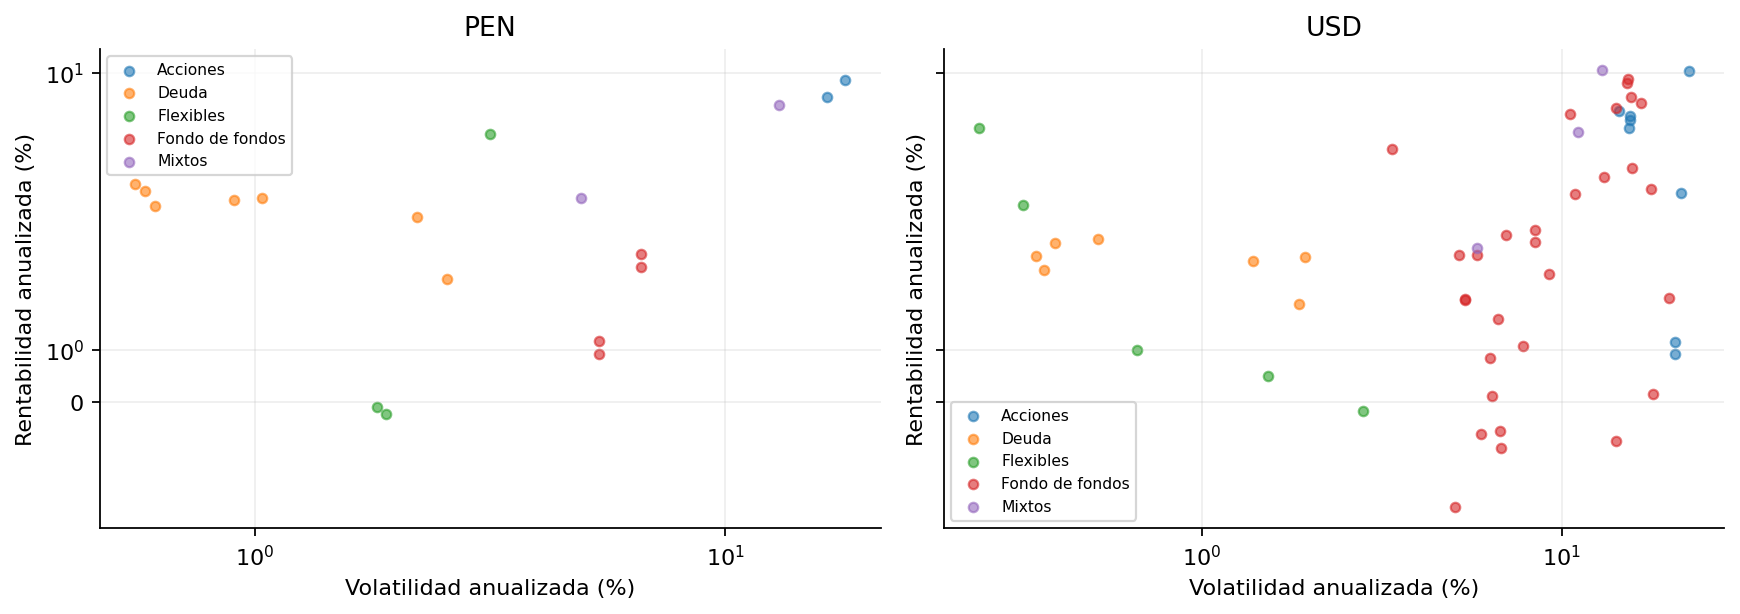

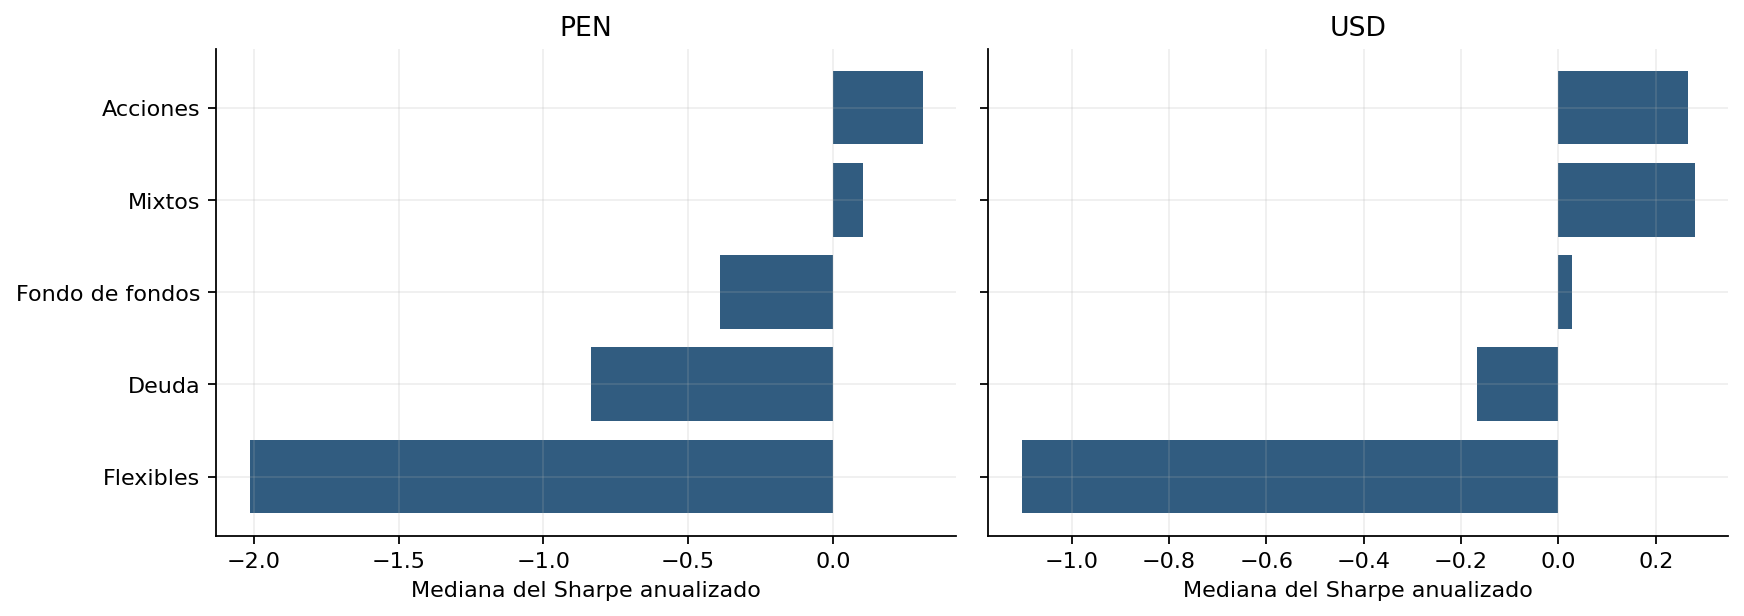

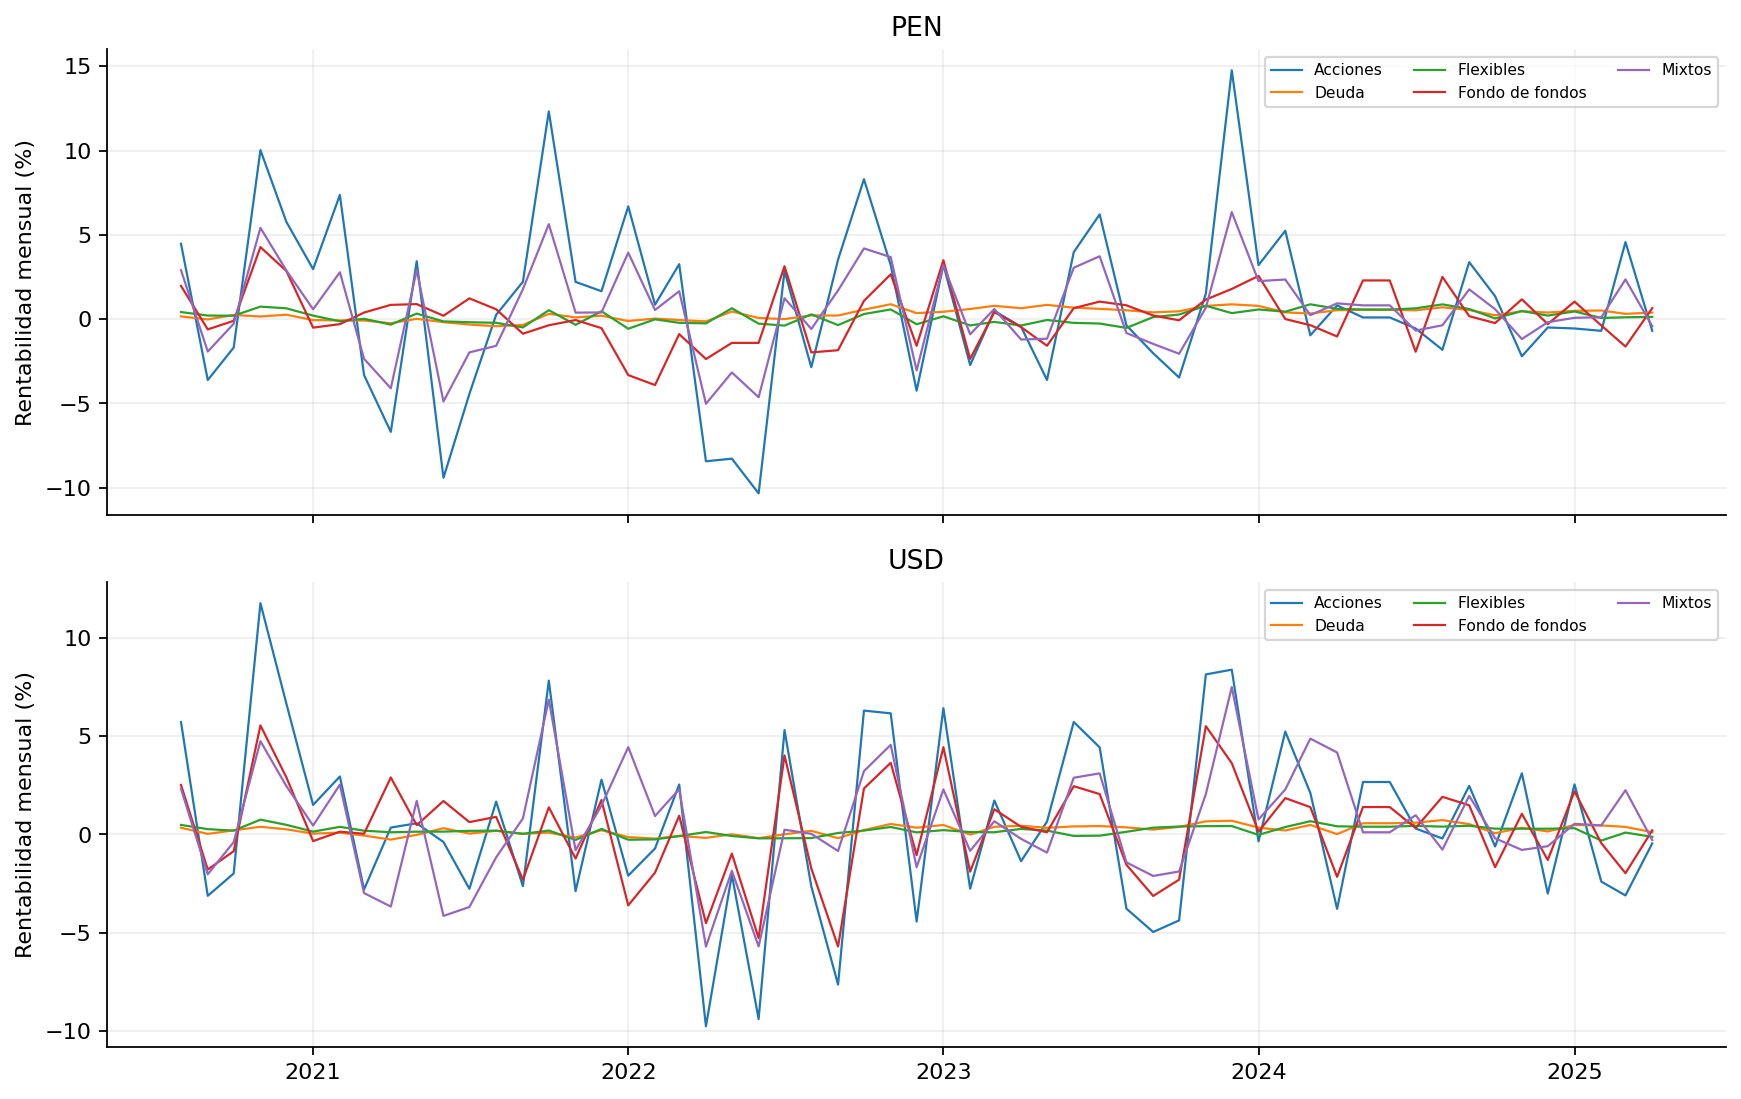

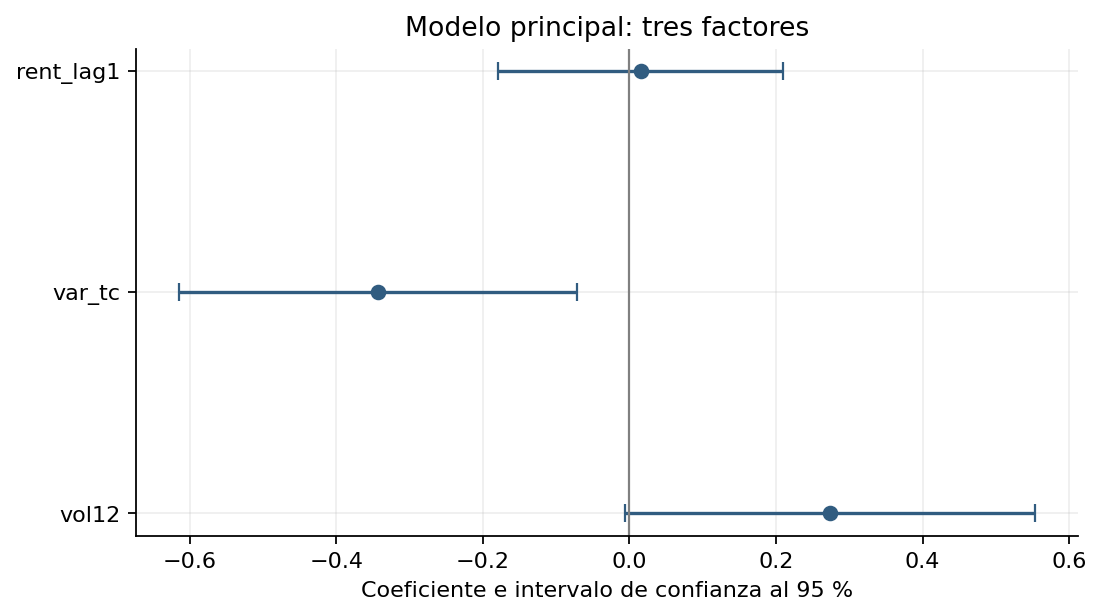

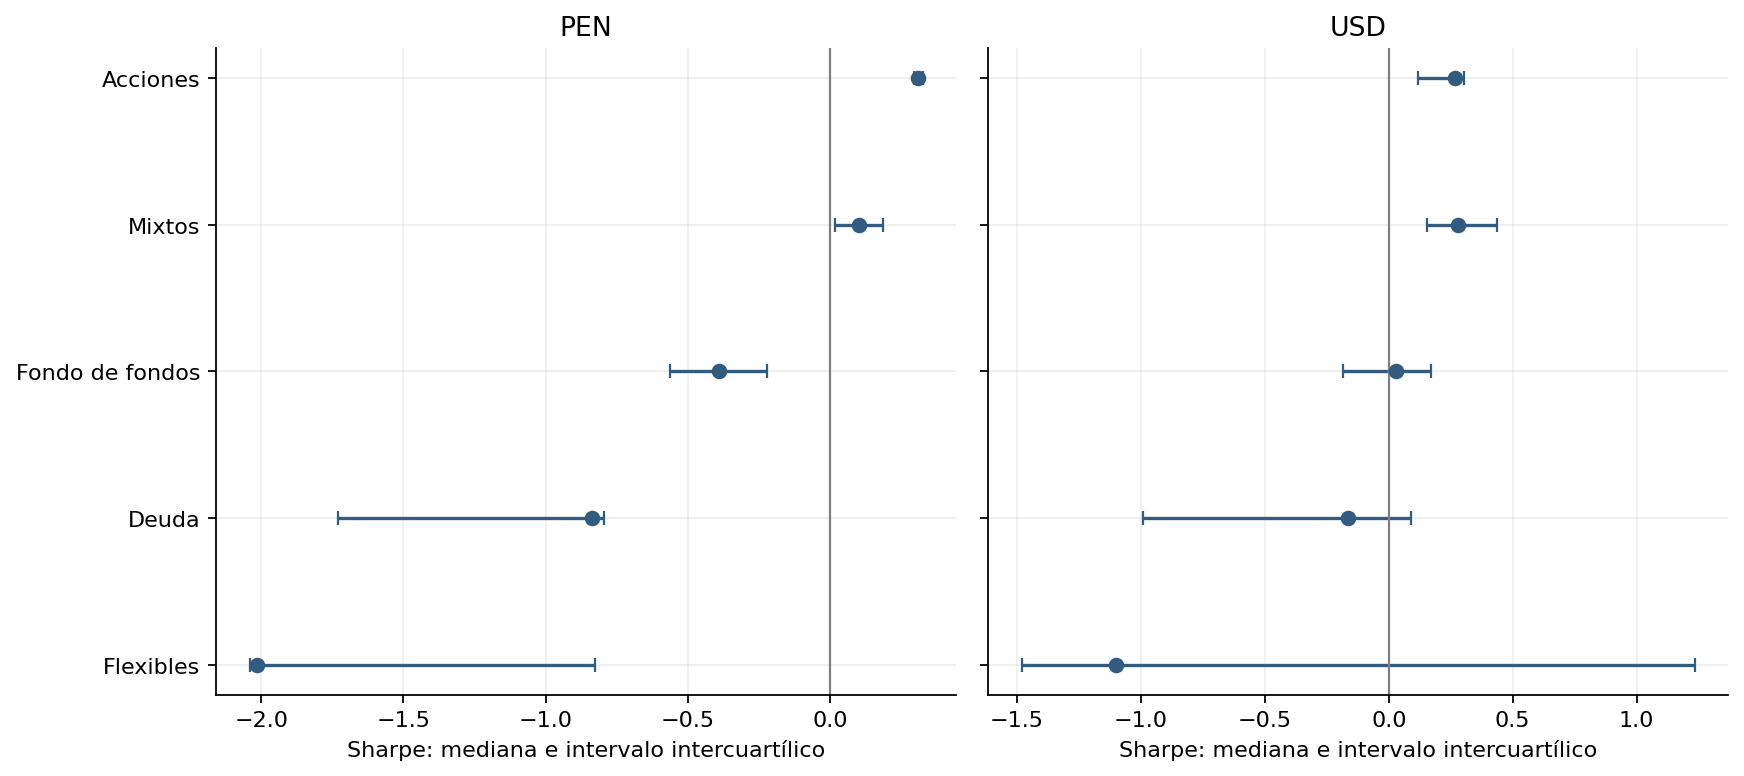

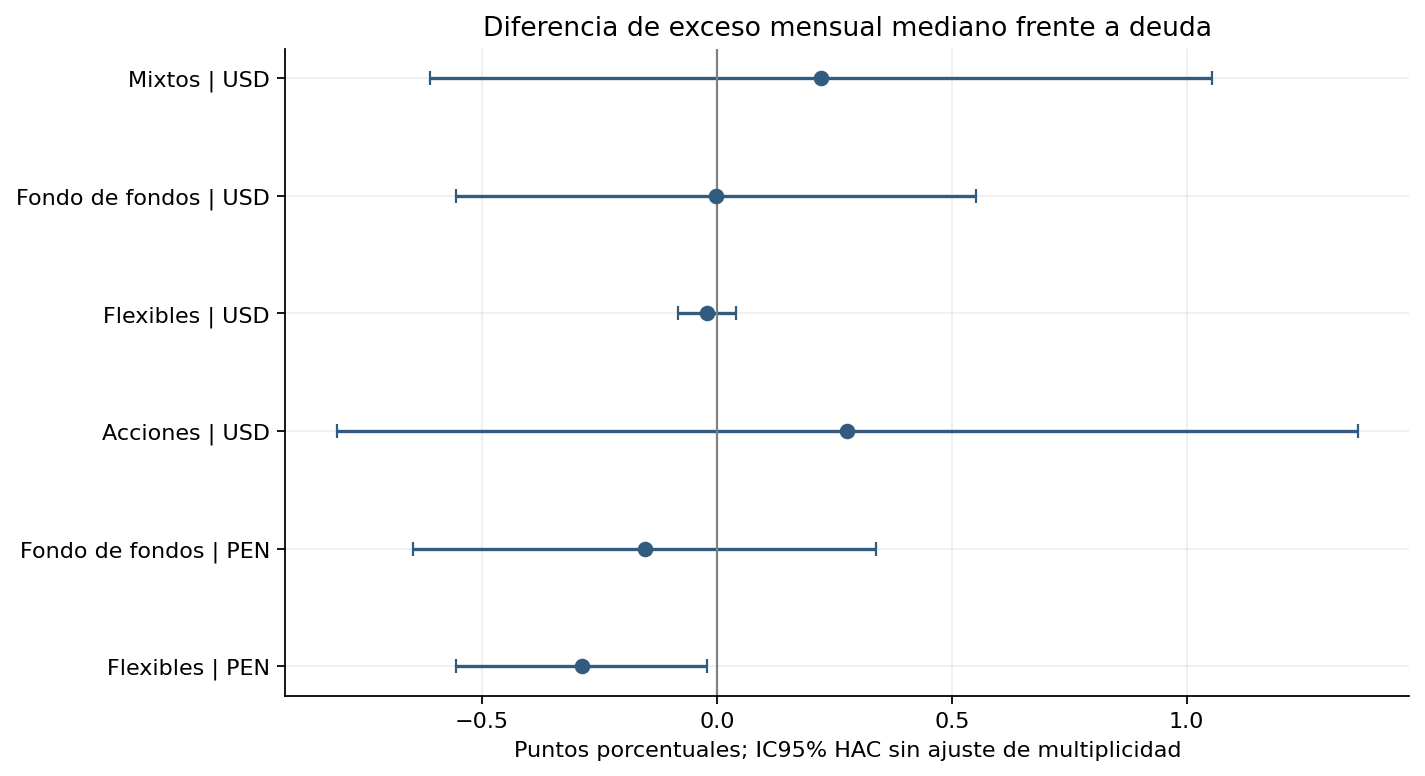

In [13]:
if ESTADO.get('04_analisis.py')!=0: raise RuntimeError('Primero termina el análisis')
from IPython.display import display, Image
import csv, itertools
for p in sorted(Path('salidas').glob('tabla*.csv')):
    print(p.name)
    with p.open(encoding='utf-8',newline='') as archivo:
        for fila in itertools.islice(csv.reader(archivo),12):print(' | '.join(fila))
for p in sorted(Path('salidas').glob('figura*.png')):
    display(Image(filename=str(p),width=850))

## Paso 8. Verificación integral (quinto script voluntario)
El flujo automático verifica integridad y reproducción local antes de publicar. El mismo script permite cotejar las fuentes vivas desde un clon limpio, sin reemplazar los crudos.


In [14]:
%%writefile codigo/05_verificacion_fuente.py
# Autora: Amy Pamela Guadalupe Cordova
# Código de matrícula: 2024200501G
# Tema 79: Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo
# Fecha de extracción: 2026-11-20
"""Auditoría independiente de integridad, reproducción y autenticidad.

La ejecución sin argumentos reproduce la entrega y realiza un cotejo acotado
contra ambas fuentes vivas. --en-vivo comprueba solo la muestra en la exposición;
--sin-internet verifica íntegramente la reproducción desde JSON y PDF entregados.
La comparación en vivo NO acredita todos los meses; una respuesta bloqueada no
es una discrepancia de datos. Nunca se regeneran los hashes de la entrega ni se
sobrescriben los crudos. Código de salida 0: pruebas solicitadas conformes;
2: cotejo vivo incompleto o discrepante; 1: error de integridad/reproducción.
"""
from pathlib import Path
from datetime import datetime, timezone, timedelta
import argparse
import hashlib
import importlib.util
import shutil
import subprocess
import sys
import tempfile
import numpy as np
import pandas as pd

RAIZ = Path(__file__).resolve().parents[1]
SALIDAS = RAIZ / 'salidas'
PROCESADO = 'datos_procesados/datos_procesados_2024200501G.csv'
CRUDO_AAF = 'datos_crudos/datos_crudos_2024200501G_aaf.csv'
CRUDO_BCRP = 'datos_crudos/datos_crudos_2024200501G_bcrp.csv'
INVENTARIO = 'datos_crudos/scraping/descargas_boletines_2024200501G.csv'
SEMILLA = 501  # 0501: últimos cuatro dígitos numéricos de la matrícula.
UMBRAL = .95
RTOL, ATOL = 1e-9, 1e-11
LLAVES = ['id_fondo_serie','mes','fecha','codigo','denominacion_original','moneda','tipo','variable','archivo']


def sha(p):
    """Calcula la huella de los bytes originales, sin abrir ni modificar datos."""
    return hashlib.sha256(p.read_bytes()).hexdigest()


def leer_csv(p):
    return pd.read_csv(p, dtype={'mes':str})


def fecha_peru():
    return datetime.now(timezone(timedelta(hours=-5))).isoformat(timespec='seconds')


def igual(a,b):
    """Compara números con tolerancia de serialización, no de revisión oficial."""
    if pd.isna(a) or pd.isna(b):
        return bool(pd.isna(a) and pd.isna(b))
    try:
        return bool(np.isclose(float(a),float(b),rtol=RTOL,atol=ATOL))
    except (ValueError,TypeError):
        return str(a)==str(b)


def integridad():
    """Prueba 1: el manifiesto se coteja antes de reejecutar, nunca después."""
    rutas=[]
    for num,linea in enumerate((RAIZ/'hash_sha256.txt').read_text(encoding='utf-8').splitlines(),1):
        esperado,rel=linea.split('  ',1)
        r=Path(rel)
        if r.is_absolute() or '..' in r.parts or rel in rutas:
            raise RuntimeError(f'Manifiesto inválido en línea {num}: {rel}')
        p=RAIZ/r
        if not p.is_file() or sha(p)!=esperado:
            raise RuntimeError('Hash no coincide con archivo entregado: '+rel)
        rutas.append(rel)
    if not {PROCESADO,CRUDO_AAF,CRUDO_BCRP,INVENTARIO}.issubset(rutas):
        raise RuntimeError('Manifiesto incompleto.')
    print(f'PRUEBA 1 | Integridad original: {len(rutas)} archivos conformes.')
    return rutas


def comparar_csv(a,b):
    """Prueba las dimensiones, columnas, tipos inferidos y claves antes de valores.
    Los números pueden diferir en el último decimal al ejecutar otro entorno.
    Los identificadores y fechas nunca admiten tolerancia numérica.
    """
    x,y=leer_csv(a),leer_csv(b)
    forma=x.shape==y.shape and list(x.columns)==list(y.columns)
    tipos=forma and x.dtypes.astype(str).equals(y.dtypes.astype(str))
    if not forma or not tipos:
        return dict(filas_original=len(x),filas_reproducidas=len(y),columnas_tipos=bool(tipos),claves=False,celdas=0,coinciden=0,equivalencia=0.)
    # Comparar texto exacto en identificadores y campos no numéricos.
    claves=all(x[k].equals(y[k]) for k in LLAVES if k in x)
    ok=x.eq(y)|(x.isna()&y.isna())
    for col in x:
        if col not in LLAVES and pd.api.types.is_numeric_dtype(x[col]):
            ok[col]=np.isclose(x[col].to_numpy(dtype=float),y[col].to_numpy(dtype=float),rtol=RTOL,atol=ATOL,equal_nan=True)
    total=ok.size; n=int(ok.to_numpy().sum())
    return dict(filas_original=len(x),filas_reproducidas=len(y),columnas_tipos=bool(tipos),claves=bool(claves),celdas=total,coinciden=n,equivalencia=n/total if total else 1.)


def copia_temporal(t):
    """Aísla toda actividad de red, logs y reejecución de los datos entregados."""
    for carpeta in ['codigo','datos_crudos']:
        shutil.copytree(RAIZ/carpeta,t/carpeta,ignore=shutil.ignore_patterns('__pycache__','*.ipynb'))
    for carpeta in ['datos_procesados','salidas']:
        (t/carpeta).mkdir()


def muestra_panel():
    """Muestra elegida antes de consultar, solo en registros originales observados.
    No se compara un retorno winsorizado/interpolado con un dato publicado.
    Se usa el identificador homologado para encontrar t y t-1.
    """
    d=leer_csv(RAIZ/PROCESADO)
    observado=leer_csv(RAIZ/'datos_procesados/base_integrada_observada.csv')
    llaves=set(zip(observado.id_fondo_serie,observado.mes))
    manifiesto=leer_csv(RAIZ/INVENTARIO)
    meses=set(manifiesto.mes)
    a=d[d.muestra_modelo.eq(1)&d.imputado.eq(0)]
    for mes,g in reversed(list(a.groupby('mes',sort=True))):
        previo=str(pd.Period(mes,freq='M')-1)
        if mes not in meses or previo not in meses:continue
        elegible=g[g.id_fondo_serie.map(lambda k:(k,mes) in llaves and (k,previo) in llaves)]
        if len(elegible)>=10:
            return elegible.sort_values('id_fondo_serie').sample(10,random_state=SEMILLA).reset_index(drop=True)
    raise RuntimeError('No existen diez casos con datos originales verificables de t y t-1.')


def informe_local(rutas):
    """Pruebas 2 a 4: reparsear originales, recalcular procesado y regenerar salidas.
    No necesita permisos de GitHub, Drive ni acceso a Internet.
    """
    registro=[f'# Verificación computacional local\n\nFecha de ejecución: {fecha_peru()}',
              f'Prueba 1. Integridad: {len(rutas)} hashes originales conformes.',
              'Prueba 2. Reparseo de JSON de BCRP y PDF AAF entregados.',
              'Prueba 3. Reestimación de limpieza, variables calculadas, tablas y modelos desde los crudos.']
    comparaciones=[]
    with tempfile.TemporaryDirectory(prefix='repro_finanzas_') as tmp:
        t=Path(tmp);copia_temporal(t)
        # Si estos productos ya existían, borrarlos solo en la copia para asegurar
        # que realmente se generen con el código y no se reutilicen archivos viejos.
        for rel in [CRUDO_BCRP,CRUDO_AAF,'datos_crudos/scraping/control_parseo_2024200501G.csv','datos_crudos/scraping/filas_no_reconocidas_2024200501G.csv']:
            (t/rel).unlink(missing_ok=True)
        orden=[('01_extraccion_api.py','--local'),('02_scraping_web.py','--local'),('03_limpieza_datos.py',),('04_analisis.py',)]
        for args in orden:
            subprocess.run([sys.executable,str(t/'codigo'/args[0]),*args[1:]],cwd=t,check=True)
        for rel in rutas:
            if not rel.endswith('.csv'):
                continue
            if not (t/rel).is_file():
                raise RuntimeError('Archivo CSV no reproducido: '+rel)
            resultado=comparar_csv(RAIZ/rel,t/rel)
            comparaciones.append(dict(archivo=rel,**resultado))
        df=pd.DataFrame(comparaciones)
        df.to_csv(SALIDAS/'verificacion_equivalencia.csv',index=False,float_format='%.12g')
        if df.empty or not df.columnas_tipos.all() or not df.claves.all() or (df.equivalencia<UMBRAL).any():
            raise RuntimeError('Reproducción no conforme; revisar verificacion_equivalencia.csv')
        originales={p.name for p in SALIDAS.glob('figura*.png')}
        nuevos={p.name for p in (t/'salidas').glob('figura*.png')}
        if not originales or originales!=nuevos or any((t/'salidas'/n).stat().st_size==0 for n in nuevos):
            raise RuntimeError('No se regeneraron todas las figuras.')
        registro.append(f'Prueba 4. {len(df)} CSV equivalentes al umbral del 95%; mínimo observado {df.equivalencia.min():.2%}. {len(nuevos)} figuras regeneradas; no se exige identidad de bytes PNG entre plataformas.')
        registro.extend(f'- {r.archivo}: {r.coinciden}/{r.celdas} celdas ({r.equivalencia:.2%}); tipos y claves conformes.' for r in df.itertuples())
    muestra_panel().to_csv(SALIDAS/'muestra_cotejo_2024200501G.csv',index=False)
    registro.append('APROBADO: reproducción computacional local. No equivale a acreditar una consulta nueva de las fuentes vivas.')
    (SALIDAS/'verificacion_local.md').write_text('\n\n'.join(registro)+'\n',encoding='utf-8')
    print('\n'.join(registro))


def importar(ruta,nombre):
    """Carga una función de extracción desde la copia temporal, sin ejecutarla."""
    spec=importlib.util.spec_from_file_location(nombre,ruta)
    mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod)
    return mod


def cotejo_vivo():
    """Pruebas 5 y 6: consultas auténticas, acotadas al periodo de la muestra.
    Se consultan dos boletines (t y t-1) y tres series BCRP. Se cotejan las diez
    filas seleccionadas y los valores utilizados para calcular el exceso y X2.
    La volatilidad histórica de 12 meses se coteja íntegramente en modo local,
    no se afirma haber reextraído sus 12 boletines en esta demostración.
    """
    muestra=muestra_panel();mes=muestra.mes.iloc[0];previo=str(pd.Period(mes,freq='M')-1)
    manifiesto=leer_csv(RAIZ/INVENTARIO).set_index('mes')
    original_b=leer_csv(RAIZ/CRUDO_BCRP);original_b['fecha']=pd.to_datetime(original_b.fecha)
    errores=[];comps=[];fuentes=[];bcrp={};aaf={}
    def comparar(fuente,clave,campo,original,vivo,url,pagina='',encontrado=True):
        comps.append(dict(fuente=fuente,clave=clave,variable=campo,entregado=original,consultado=vivo,url=url,pagina=pagina,coincide=bool(encontrado and igual(original,vivo))))
    with tempfile.TemporaryDirectory(prefix='cotejo_fuentes_') as tmp:
        t=Path(tmp);copia_temporal(t)
        api=importar(t/'codigo/01_extraccion_api.py','aporte_bcrp')
        pdf=importar(t/'codigo/02_scraping_web.py','aporte_aaf')
        limpieza=importar(t/'codigo/03_limpieza_datos.py','identificadores')
        inicio=previo+'-01';fin=str(pd.Period(mes,freq='M').end_time.date())
        print(f'PRUEBA 5 | BCRP: ventana {inicio} a {fin}.')
        for codigo in api.SERIES:
            direccion=api.url(codigo,inicio,fin)
            try:
                contenido=api.consultar(direccion)
                nuevo=api.leer(codigo,contenido)
                antiguo=original_b[original_b.codigo.eq(codigo)&original_b.fecha.between(inicio,fin)]
                a=antiguo.set_index('fecha').valor_original;b=nuevo.set_index('fecha').valor_original
                if a.empty or b.empty:raise RuntimeError('Consulta sin registros para cotejar')
                bcrp[codigo]=nuevo
                for periodo in sorted(set(a.index)|set(b.index)):
                    comparar('BCRP',f'{codigo} | {periodo:%Y-%m-%d}','valor_original',a.get(periodo),b.get(periodo),direccion,encontrado=periodo in a.index and periodo in b.index)
                fuentes.append(f'BCRP {codigo}: {len(a)} registros entregados y {len(b)} consultados.')
            except Exception as e:
                errores.append(f'BCRP {codigo}: {type(e).__name__}: {e}')
                # Ante un rechazo explícito, no seguir consultando el portal.
                if any(c in str(e) for c in ['401','403','418','429']):break
        print(f'PRUEBA 6 | AAF: boletines {previo} y {mes}; muestra aleatoria de diez filas.')
        try:
            reglas=pdf.reglas_portal()
            for p in [previo,mes]:
                row=manifiesto.loc[p]
                contenido=pdf.pedir(row.url,reglas)
                if not contenido.startswith(b'%PDF'):raise RuntimeError('La respuesta no es PDF: '+row.url)
                ruta=t/'datos_crudos/scraping/pdf_boletines'/row.archivo
                # Únicamente en copia temporal; los bytes de la entrega permanecen intactos.
                ruta.write_bytes(contenido)
                filas,_,candidatos=pdf.leer_pdf(ruta,p)
                if len(filas)<25 or not candidatos or len(filas)/candidatos<.90:
                    raise RuntimeError('Formato AAF distinto o parseo insuficiente: '+p)
                aaf[p]=pd.DataFrame(filas)
                aaf[p]['id_fondo_serie']=[limpieza.identidad(f,z,c) for f,z,c in zip(aaf[p].fondo,aaf[p].administradora,aaf[p].moneda)]
                fuentes.append(f'AAF {p}: {len(filas)} filas reconocidas. SHA original igual: {sha(ruta)==row.sha256}.')
        except Exception as e:
            errores.append(f'AAF: {type(e).__name__}: {e}')
        # Se cotejan las cifras originales (no las tratadas); se conserva URL/página.
        for r in muestra.itertuples():
            if mes in aaf:
                h=aaf[mes];z=h[h.id_fondo_serie.eq(r.id_fondo_serie)&h.moneda.eq(r.moneda)&h.tipo.eq(r.tipo)].drop_duplicates(['valor_cuota','rent_mes'])
                unico=len(z)==1
                for campo,entregado in [('rent_original',r.rent_original),('valor_cuota',r.valor_cuota)]:
                    campo_fuente='rent_mes' if campo=='rent_original' else campo
                    comparar('AAF',r.id_fondo_serie+' | '+mes,campo,entregado,z.iloc[0][campo_fuente] if unico else None,manifiesto.loc[mes].url,int(z.iloc[0].pagina) if unico else '',unico)
            if previo in aaf:
                h=aaf[previo];z=h[h.id_fondo_serie.eq(r.id_fondo_serie)&h.moneda.eq(r.moneda)&h.tipo.eq(r.tipo)].drop_duplicates(['rent_mes'])
                unico=len(z)==1
                comparar('AAF',r.id_fondo_serie+' | '+previo,'rent_lag1_original',r.rent_lag1_original,z.iloc[0].rent_mes if unico else None,manifiesto.loc[previo].url,int(z.iloc[0].pagina) if unico else '',unico)
        # Recalcular las variables macroeconómicas desde registros recién consultados.
        if len(bcrp)==3:
            valores={}
            for codigo,h in bcrp.items():
                h=h.copy();h['mes']=h.fecha.dt.to_period('M').astype(str);h['valor']=pd.to_numeric(h.valor_original,errors='coerce')
                valores[codigo]=h.groupby('mes').valor.mean()
            tc=valores['PN01216PM'];var=np.log(tc.get(mes,np.nan))-np.log(tc.get(previo,np.nan))
            for r in muestra.itertuples():
                tc_url=api.url('PN01216PM',inicio,fin)
                comparar('BCRP_calculo',r.id_fondo_serie+' | '+mes,'tc_fin',r.tc_fin,tc.get(mes),tc_url)
                comparar('BCRP_calculo',r.id_fondo_serie+' | '+mes,'var_tc',r.var_tc,var,tc_url)
                cod='PD04692MD' if r.moneda=='PEN' else 'PD04693MD';tasa=valores[cod].get(mes,np.nan);rf=(1+tasa/100)**(1/12)-1
                comparar('BCRP_calculo',r.id_fondo_serie+' | '+mes,'rf_mensual',r.rf_mensual,rf,api.url(cod,inicio,fin))
    # El informe se guarda aparte del conjunto de archivos sellados con hash.
    tab=pd.DataFrame(comps,columns=['fuente','clave','variable','entregado','consultado','url','pagina','coincide'])
    tab.to_csv(SALIDAS/'verificacion_cotejo_vivo.csv',index=False)
    resumen=tab.groupby('fuente').coincide.agg(['sum','count']) if not tab.empty else pd.DataFrame()
    completo=not errores and len(bcrp)==3 and len(aaf)==2 and len(tab[tab.fuente.eq('AAF')])==30 and len(tab[tab.fuente.eq('BCRP_calculo')])==30
    # Una discrepancia no se justifica como revisión oficial sin evidencia.
    conforme=bool(completo and not tab.empty and tab.coincide.all())
    estado='CONFORME: muestra viva cotejada completamente' if conforme else ('NO VERIFICABLE COMPLETAMENTE: acceso o cobertura insuficiente' if not completo else 'DISCREPANCIAS: revisar los registros y posibles revisiones oficiales')
    lineas=['# Cotejo en vivo de ambas fuentes',f'Fecha de consulta: {fecha_peru()}',f'Muestra: diez fondo/serie-mes de {mes}; semilla {SEMILLA}; mes previo {previo}.',*fuentes,'Coincidencias por fuente:',resumen.to_string(),*errores,estado,'Alcance: muestra acotada. No certifica todos los PDF ni todas las fechas. No se reextrae vol12 en vivo; se cotejan rentabilidades publicadas antes de winsorizar y filas no interpoladas. Los originales y hashes se conservan.']
    (SALIDAS/'verificacion_en_vivo.md').write_text('\n\n'.join(lineas)+'\n',encoding='utf-8')
    print('\n'.join(lineas))
    print(tab.loc[tab.fuente.eq('AAF'),['clave','variable','entregado','consultado','pagina','coincide']].to_string(index=False))
    return conforme


def main():
    p=argparse.ArgumentParser(description=__doc__)
    g=p.add_mutually_exclusive_group()
    g.add_argument('--sin-internet',action='store_true',help='Reproducción íntegra sin acceso a las fuentes')
    g.add_argument('--en-vivo',action='store_true',help='Cotejo acotado para la exposición')
    a=p.parse_args()
    rutas=integridad()
    vivo_ok=True
    if not a.sin_internet:vivo_ok=cotejo_vivo()
    if not a.en_vivo:informe_local(rutas)
    # Confirma la integridad otra vez para detectar cualquier modificación accidental.
    integridad()
    if not vivo_ok:sys.exit(2)


if __name__=='__main__':main()


Writing codigo/05_verificacion_fuente.py


### Documentación y hash de los archivos originales, antes de reproducir

In [18]:
import hashlib, re
if ESTADO.get('04_analisis.py')!=0: raise RuntimeError('No se generan evidencias de una ejecución incompleta')
log=Path('log_ejecucion.txt').read_text(encoding='utf-8')
fechas_api=re.findall(r'^(\d{4}-\d{2}-\d{2}).*\| 01_api \| GUARDADO',log,re.M)
if not fechas_api: raise RuntimeError('No consta extracción real API en el log')
import csv
def leer_csv(ruta):
    with open(ruta,encoding='utf-8',newline='') as f:return list(csv.DictReader(f))
manifest=leer_csv('datos_crudos/scraping/descargas_boletines_2024200501G.csv')
f_aaf=sorted(r['fecha_consulta'][:10] for r in manifest)
fecha_extraccion=max(fechas_api[-1],f_aaf[-1])
for p in Path('codigo').glob('*.py'):
    lineas=p.read_text(encoding='utf-8').splitlines(keepends=True)
    lineas[3]=f'# Fecha de extracción: {fecha_extraccion}\n'
    p.write_text(''.join(lineas),encoding='utf-8')
# Huellas de respuestas originales, bases y resultados generados (no incluye el propio informe 05).
archivos=[p for nombre in ['datos_crudos','datos_procesados','salidas'] for p in Path(nombre).rglob('*') if p.is_file() and p.name not in ['verificacion_local.md','muestra_cotejo_2024200501G.csv','verificacion_equivalencia.csv','verificacion_cotejo_vivo.csv','verificacion_en_vivo.md']]
archivos.append(Path('documentos/captura_bloqueo_smv.png'))
Path('hash_sha256.txt').write_text(''.join(f'{hashlib.sha256(p.read_bytes()).hexdigest()}  {p.as_posix()}\n' for p in sorted(archivos)),encoding='utf-8')
d=leer_csv('datos_procesados/datos_procesados_2024200501G.csv')
cob=leer_csv('salidas/tabla_cobertura_variables.csv')
meses_observados=sorted({r['mes'] for r in d})
n_unidades=len({r['id_fondo_serie'] for r in d})
n_modelo=sum(int(r['muestra_modelo']) for r in d)
sha=hashlib.sha256(Path('datos_procesados/datos_procesados_2024200501G.csv').read_bytes()).hexdigest()
mes_inicio,mes_fin=meses_observados[0],meses_observados[-1]
meses_es='enero febrero marzo abril mayo junio julio agosto septiembre octubre noviembre diciembre'.split()
def fecha_apa(s):
    x=datetime.fromisoformat(s);return f'{x.day} de {meses_es[x.month-1]} de {x.year}'
referencias=f"""Banco Central de Reserva del Perú. (s. f.). *BCRPData: Series estadísticas de tipo de cambio e interbancarias* [Conjunto de datos]. Recuperado el {fecha_apa(fechas_api[-1])}, de https://estadisticas.bcrp.gob.pe/estadisticas/series/

Asociación de Administradoras de Fondos del Perú. (s. f.). *Estadísticas mensuales de fondos mutuos* [Informes estadísticos]. Recuperado el {fecha_apa(f_aaf[-1])}, de https://fondosmutuos.pe/estadisticas/ (consultas registradas del {fecha_apa(f_aaf[0])} al {fecha_apa(f_aaf[-1])})."""
# Todos los conteos, fechas e inventarios se generan desde la ejecución actual.
b=leer_csv('datos_crudos/datos_crudos_2024200501G_bcrp.csv')
a=leer_csv('datos_crudos/datos_crudos_2024200501G_aaf.csv')
control=leer_csv('datos_crudos/scraping/control_parseo_2024200501G.csv')
import pandas as pd
import importlib.metadata as meta
n_aceptados=sum(str(r['aceptado']).lower()=='true' for r in control)
periodos=pd.period_range(mes_inicio,mes_fin,freq='M').astype(str)
faltan=', '.join(x for x in periodos if x not in meses_observados) or 'Ninguno'
modelos=[r for r in d if int(r['muestra_modelo'])==1]
filas_cob='\n'.join('| {variable} | {observaciones_validas} | {meses_distintos} |'.format(**r) for r in cob)
base_api='https://estadisticas.bcrp.gob.pe/estadisticas/series/api'
series={r['codigo']:r for r in b}
filas_api='\n'.join('| '+ ' | '.join([k,r['nombre_serie'],r['frecuencia'],r['unidad'],f'`{base_api}/{k}/json/'+('2018-12/2025-12' if r['frecuencia']=='mensual' else '2018-12-01/2025-12-31')+'/esp`'])+' |' for k,r in series.items())
filas_versiones='\n'.join(f'| {k} | {meta.version(k)} |' for k in VERSIONES)
filas_salidas='\n'.join(f'- `{p.as_posix()}`' for p in sorted(Path('salidas').glob('*')) if p.is_file() and not p.name.startswith(('verificacion','muestra_cotejo')))
PLANTILLA_README = r"""# Fondos mutuos en el Perú: rentabilidad y riesgo por tipo de fondo

## 1. Identificación académica

- **Autora:** Amy Pamela Guadalupe Cordova
- **Código:** 2024200501G
- **Universidad:** Universidad Nacional del Centro del Perú, Facultad de Economía, Escuela Profesional de Economía.
- **Curso:** Finanzas I (055D), 2026-II, Unidad II.
- **Docente:** Dr. Ciro Iván Machacuay Meza.
- **Tema 79 (S12):** Diversificación y gestión del riesgo.
- **Repositorio:** https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo

## 2. Objetivo y alcance

Comparar el desempeño ajustado por riesgo de los fondos mutuos peruanos por tipo y moneda.

Objetivos específicos operativos:

1. Construir un panel mensual a partir de boletines publicados y series del BCRP.
2. Medir rentabilidad, volatilidad y Sharpe anualizados por denominación/serie y resumir sus distribuciones por categoría.
3. Estimar la asociación de tres factores con la rentabilidad mensual y examinar la sensibilidad de la inferencia.
4. Comparar el exceso de rentabilidad y el Sharpe de grupos en ventanas comunes, declarando las limitaciones.

El diseño es observacional, longitudinal, de panel balanceado. No identifica causalidad ni recomienda comprar fondos.
La unidad es fondo-serie homologado por administradora, denominación y moneda, observado o estimado en un mes; no es un identificador registral SMV. Varias clases pueden pertenecer al mismo fondo. La homologación conserva series y moneda; se registran las variantes exactas y se excluyen conflictos. No se usa coincidencia difusa automática. Las comparaciones dan igual peso a las series observadas, no a patrimonio ni partícipes.

## 3. Fuentes y endpoints exactos

**Vía 1: API REST BCRPData**, pública y sin clave de API. Los nombres de las series proceden de los metadatos JSON.

| Código | Serie publicada | Frecuencia | Unidad | Endpoint congelado |
|---|---|---|---|---|
{filas_api}

- `FECHA_INICIO = 2018-12-01`; `FECHA_CORTE = 2025-12-31`. El mes previo permite calcular la variación cambiaria desde enero de 2019.
- Se conserva cada respuesta JSON íntegra en `datos_crudos/api/` y su CSV tabular asociado, incluyendo valores no numéricos originales.
- La media mensual de las tasas diarias usa solo valores numéricos observados. El tipo de cambio mensual ya corresponde a fin de periodo; no se inventan días.

**Vía 2: descarga programática de boletines AAF** (Asociación de Administradoras de Fondos del Perú).

- Catálogo: https://fondosmutuos.pe/estadisticas/.
- Reglas de rastreo: https://fondosmutuos.pe/robots.txt.
- Boletín piloto: https://fondosmutuos.pe/wp-content/uploads/2025/02/Boletin-Enero-2025-9.pdf.
- El inventario `datos_crudos/scraping/descargas_boletines_2024200501G.csv` contiene cada URL consultada con resultado PDF válido, fecha, HTTP y SHA-256. El archivo `listado_aaf.html` conserva el catálogo consultado.
- Ventana congelada del catálogo: `2019-01` a `2025-12`, constantes del script 02. Se analizan hipervínculos `a[href]` a PDF de boletines y sus encabezados `h1` a `h6` y nombres de archivo; no se inventa una paginación. La lectura usa PyMuPDF (formatos anteriores a diciembre de 2022) y pdfplumber (formatos modernos), área visible, portada, encabezados de categoría y patrones de columnas. Se comprueban ambos formatos con dos pilotos. Se rechazan los PDF cuya portada no coincide o con capas superpuestas que impiden validar el tipo: por ejemplo, el enlace de junio de 2024 no declara junio y diciembre de 2025 tiene texto superpuesto. El control de parseo registra las incidencias.
- Se exige al menos 25 filas reconocidas y 90 % de líneas candidatas identificadas por boletín. Esta tasa se refiere al parser, no prueba que el universo publicado esté completo. Se guarda el texto de cada fila, página y archivo.
- Se respetan robots.txt, redirecciones normales del portal, User-Agent identificable y pausas de 1,5 segundos. Ante rechazo explícito se detiene el acceso; enlaces 404/410 o que no son PDF se registran. No se navega alrededor de un bloqueo.

**Justificación y límite institucional.** El tema 79 del temario sugiere SMV diaria y BCRPData; AAF no aparece nombrada como fuente sugerida. La rúbrica 2.4.1 admite otras fuentes y 2.4.3 permite PDF descargados y parseados programáticamente, preservando su original. El bloqueo de SMV (HTTP 418) está descrito en `incidencias_fuente.md`. No se afirma contar con autorización docente de sustitución sin constancia real. Los boletines son publicaciones de la asociación, no una descarga directa de la SMV. El boletín de enero de 2025, página 7, declara que sus datos se obtuvieron del portal SMV para el periodo correspondiente; precisa que las rentabilidades no incluyen comisiones de suscripción/rescate ni impuesto a la renta. La captura original `documentos/captura_bloqueo_smv.png` acredita el rechazo HTTP 418 del intento de la Unidad II. Sigue siendo necesario registrar la autorización escrita prevista en 2.4.3 si corresponde.

## 4. Cobertura observada y control de tamaño

Fecha de consulta API: {fecha_api}; consultas AAF: {fecha_aaf_ini} a {fecha_aaf_fin}.

| Indicador | Valor |
|---|---:|
| Registros crudos BCRP (diarios y mensuales) | {n_b} |
| Filas crudas reconocidas AAF | {n_a} |
| PDF originales conservados | {n_pdf} |
| Boletines aceptados por parser | {n_aceptados} |
| Boletines descargados excluidos por parser | {n_rechazados} |
| Periodo observado en panel | {mes_inicio} a {mes_fin} |
| Meses calendario del panel | {n_meses} |
| Meses legibles en crudo AAF | {n_meses_crudo} |
| Filas interpoladas del panel | {n_imputadas} |
| Filas con retorno winsorizado | {n_winsor} |
| Valores faltantes de la base definitiva | {n_faltantes} |
| Tipos presentes en panel | {tipos_panel} |
| Tipos solo en análisis contextual | {tipos_fuera} |
| Meses faltantes dentro del periodo observado | {faltan} |
| Filas finales y columnas | {n_panel} × {n_cols} |
| Denominaciones/series distintas | {n_unidades} |
| Filas completas en MCO | {n_modelo} |
| Meses de estimación | {n_modelo_meses} |
| Series de estimación | {n_modelo_series} |

| Variable | Filas válidas | Meses distintos |
|---|---:|---:|
{filas_cob}

El control del script 03 exige al menos 4 000 filas completas, sin NA ni duplicados, con todas las unidades sobre exactamente los mismos meses. Esta es una meta interna superior al mínimo general de la rúbrica. Cada Y y X dispone de igual número de filas. La frecuencia es mensual y la cantidad de observaciones macroeconómicas independientes corresponde a los meses del panel, no a sus filas. El mínimo se interpreta como datos de panel; el tipo de cambio se repite entre fondos del mismo mes y no convierte esas repeticiones en observaciones macroeconómicas independientes. La cobertura lograda es inferior a la sugerida de 2018 a 2025 diaria y 60 000 filas; No se generan observaciones diarias artificiales ni se extrapolan series. Las interpolaciones limitadas están identificadas y no se presentan como datos publicados. No se dispone de patrimonio ni partícipes por serie de manera homogénea.

## 5. Estructura del repositorio (Carpeta N.º 3)

```text
codigo/
  00_pipeline_colab.ipynb      Cuaderno completo, ejecutable en Colab, con salidas visibles
  01_extraccion_api.py         API, JSON y crudo BCRP
  02_scraping_web.py           Catálogo, robots, boletines y crudo AAF
  03_limpieza_datos.py         Limpieza, llave, unión y variables
  04_analisis.py               Tablas, gráficos, estimación y sensibilidad
  05_verificacion_fuente.py    Integridad, reproducción y cotejo con fuente viva
datos_crudos/
  datos_crudos_2024200501G_bcrp.csv
  datos_crudos_2024200501G_aaf.csv
  api/                         Respuestas JSON completas
  scraping/                    Catálogo, robots, inventario y controles de parseo
    pdf_boletines/             Archivos PDF originales
datos_procesados/
  datos_procesados_2024200501G.csv  Panel balanceado definitivo, completo
  base_integrada_observada.csv    Registros originales depurados, antes de selección y tratamiento
salidas/                      Tablas, figuras, exclusiones y verificaciones
documentos/                   Bitácora de IA, estado de ejecución, documentación de evidencias
README.md                     Este instructivo
requirements.txt              Dependencias directas y versiones exactas
.env.example                  Nombre de la variable GitHub, sin clave
.gitignore                    Exclusiones de credenciales y caché
hash_sha256.txt                Huellas de crudos, procesado y productos empíricos
log_ejecucion.txt              Eventos, fecha, hora, HTTP y filas
incidencias_fuente.md          Bloqueo SMV y procedimiento alternativo
diccionario_variables.md       Variables, unidades, frecuencias y origen
enlace_repositorio_github.txt   URL del proyecto
```

La Carpeta N.º 1 (productos) y la N.º 2 (desarrollo de plantillas) corresponden a la entrega académica, no se declaran terminadas por ejecutar este notebook.

## 6. Reproducción desde un computador limpio

En una terminal (sin Drive ni credenciales personales):

```bash
git clone https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo.git
cd Finanzas-Segundo-Trabajo
python -m pip install -r requirements.txt
python codigo/05_verificacion_fuente.py --sin-internet
```

La verificación local comprueba primero los hashes originales, reparsea ambos crudos en una carpeta temporal y vuelve a ejecutar 03 y 04. Compara las dimensiones, tipos inferidos, claves y celdas de cada CSV. El umbral mínimo por archivo es 95 %. En particular, las figuras deben regenerarse; no se requiere igualdad binaria de PNG entre distintas plataformas.

Para reejecutar solamente los scripts de análisis sobre los crudos ya entregados, en una copia independiente:

```bash
python codigo/03_limpieza_datos.py
python codigo/04_analisis.py
```

Para extraer nuevamente desde las fuentes (solo en una copia de trabajo NUEVA, con carpetas de datos vacías; no sobrescribir la entrega sellada):

```bash
python codigo/01_extraccion_api.py
python codigo/02_scraping_web.py
python codigo/03_limpieza_datos.py
python codigo/04_analisis.py
```

La reextracción puede diferir por revisiones o disponibilidad del portal. Nunca se recalcula el hash original para ocultar diferencias. Las fechas permanecen congeladas. El notebook prepara directorios y escribe los scripts, ejecuta las etapas, genera documentación y manifiesto, verifica, guarda sus salidas visibles, descarga ZIP y publica cambios reales. Estos últimos pasos son exclusivos del flujo de la estudiante, no de la reproducción docente.

## 7. Demostración de autenticidad en vivo

Desde el clon anterior, el docente puede ejecutar:

```bash
python codigo/05_verificacion_fuente.py --en-vivo
```

El comando sin argumentos hace ambas verificaciones: `python codigo/05_verificacion_fuente.py`.
El modo de exposición es acotado y evita volver a descargar todos los boletines. Selecciona diez filas completas al azar dentro del último mes elegible, antes de consultar las fuentes (semilla 501). Consulta dos PDF consecutivos y las tres series BCRP de esa ventana, coteja cuota, rentabilidad publicada antes de winsorizar, rezago original, TC y tasa mensual de referencia; la muestra excluye filas interpoladas de t y t-1 con sus URL y página. Las series macro se cotejan también en sus fechas originales. La volatilidad histórica se verifica por reparseo y recálculo local; no se afirma consultarla íntegramente en la demostración corta.

Los informes `salidas/verificacion_equivalencia.csv` y `salidas/verificacion_local.md` documentan la reproducción local; `salidas/verificacion_cotejo_vivo.csv` y `salidas/verificacion_en_vivo.md` se crean al ejecutar el cotejo en vivo. El segundo requiere acceso real y distingue coincidencia, discrepancia y acceso no verificable. Si falla una consulta, no se usa la copia local como si fuera una respuesta nueva. El verificador no altera los originales ni los hashes; sus informes posteriores no son parte del manifiesto previo.

## 8. Versiones y credenciales

| Componente | Versión de ejecución |
|---|---|
| Python | {python_version} |
{filas_versiones}

Las API y boletines son públicos y no requieren claves. `GITHUB-TOKEN` es el nombre del secreto de Colab que utiliza únicamente la celda de publicación; `GITHUB_TOKEN` es la variable temporal de entorno usada por Git. No se incluye valor en la entrega ni se agrega el token a la URL. El script 05 no necesita token. La estudiante configura el secreto en Colab a partir de un token de su cuenta con permisos de escritura únicamente en el repositorio correspondiente. No se publica un commit si no existen cambios.

## 9. Limpieza, unión y memoria de cálculo

- Se convierte cada rentabilidad publicada en porcentaje a decimal. PDF, captura textual y CSV crudo permanecen intactos. Se excluyen retornos no numéricos, inferiores a -100 %, cuotas no positivas y administradoras no identificadas del conjunto candidato. Los registros excluidos y los duplicados conflictivos se documentan.
- Llave `id_fondo_serie`: administradora homologada mediante alias explícitos, denominación normalizada y moneda; se conservan los sufijos de clase, numerales y características distintivas. Se eliminan etiquetas genéricas de categoría/administradora repetidas y FMIV/FM como sufijos o tokens legales. Las colisiones conflictivas se excluyen, no se promedian. Se restringe a categorías estables en la historia observada. Consultar `tabla_homologacion.csv` para las variantes, no asumir que son identificadores registrales. BCRP se une mediante `mes` con cardinalidad `many_to_one`.
- Interpolación geométrica únicamente en huecos interiores de una o dos filas totalmente ausentes y delimitados por cuotas positivas. Si faltan k retornos, sea C_a la cuota anterior, C_b la cuota posterior y r_b el retorno publicado de ese mes posterior. La tasa estimada de cada mes faltante es (C_b / (C_a × (1+r_b)))^(1/k) − 1. Las cuotas intermedias se calculan acumulando esa tasa. Se preserva el retorno posterior publicado; no se reemplazan valores observados. Se rechaza la interpolación si el factor no es positivo o el retorno implícito absoluto es ≥50 %. Nunca se inventan datos antes del inicio o después del último registro, ni se interpola una tasa BCRP. Se identifica `imputado=1`, `archivo=INTERPOLACION`, `pagina=0` y se registra la evidencia de ambos meses. Posibles distribuciones o cambios de escala impiden considerar la estimación un retorno observado.
- Winsorización de retornos pretratamiento: límites Q1−3RIQ y Q3+3RIQ calculados por tipo y moneda con registros observados (no interpolados); límite inferior no menor que −100 %. Si RIQ=0 no se recorta automáticamente. El retorno utilizado es el original o estimado recortado al límite correspondiente; la cuota no se recorta. Se registran `rent_original`, `atipico`, los límites y el historial. Las X derivadas se recalculan desde la serie de retornos tratada; los crudos se conservan.
- Panel balanceado: se examinan ventanas consecutivas de mínimo 24 meses, al menos 4 tipos, historia suficiente para X1/X3, todas las variables y trazabilidad presentes. Se admite un máximo del 10 % de retornos imputados por serie en la ventana y su historial efectivamente disponible al inicio. Se elige primero una ventana de ≥60 meses que alcance 4 000 filas si existe; si no, se prioriza llegar a 4 000 filas, mayor número de tipos, luego mayor número de filas y duración. La lista de ventanas y selección se guarda. No se usa R², p ni resultados de Sharpe como criterio. Todas las series seleccionadas tienen las mismas fechas; no se obliga a los grupos a tener el mismo número de fondos. Las categorías sin suficiente historia se describen por separado con datos observados.
- Variable dependiente Y: `rent_mes`, rentabilidad mensual en decimal tras winsorización, con interpolaciones marcadas. Esta no es una función algebraica de las X del mismo periodo.
- X1 `vol12`: desviación estándar muestral de las rentabilidades tratadas de los 12 meses calendario anteriores, con mínimo 6 retornos disponibles. `historia_n`, `historia_imputada` y `historia_atipica` describen esa ventana. Se calcula también X1 sin winsorizar para sensibilidad.
- X2 `var_tc`: ln(TC_t) - ln(TC_(t-1)), con TC expresado en soles por dólar. Positivo indica depreciación del sol.
- X3 `rent_lag1`: rentabilidad tratada del mes inmediatamente anterior de la misma serie. No se usa el último dato si hubo un hueco calendario.
- Referencia `rf_mensual`: (1 + tasa_anual/100)^(1/12) - 1, seleccionada por moneda, usando la tasa interbancaria promedio de días observados como aproximación anualizada. No es una tasa libre de riesgo invertible directamente ni se afirma equivalencia exacta de convenciones de cotización.
- Exceso = retorno menos referencia. Retorno anualizado = exp(12 × promedio de ln(1+r)) - 1; cuando hay -100 % el valor se define como -100 %. Volatilidad anualizada = desviación muestral de r × raíz(12). Sharpe anualizado = media del exceso / desviación muestral del exceso × raíz(12); puede no estar definido si la desviación es cero. En la comparación principal se utilizan los meses comunes del panel (observados o estimados). En la comparación contextual se exigen al menos 12 meses observados consecutivos y se declara el horizonte de cada serie. Con autocorrelación, anualizar por raíz(12) es una convención, no una estimación garantizada del riesgo anual.
- La tasa y el TC del BCRP alimentan resultados financieros y regresiones; no son una fuente decorativa. El archivo diccionario describe cada columna por separado.

## 10. Metodología econométrica y análisis financiero

**Modelo inicial:** MCO de rent_mes sobre vol12, var_tc, rent_lag1, indicadores del tipo de fondo y moneda. Son tres regresores sustantivos; tipo/moneda son controles. Se muestra el resultado clásico como referencia y el mismo modelo con errores estándar agrupados por serie y mes como inferencia principal. Se informa R², intervalos de confianza y valores p; esto no demuestra causalidad. La variable cambiaria tiene variación temporal común; la inferencia es limitada por la cantidad de meses, aun cuando haya miles de filas.

**Diagnóstico:** VIF, rango de la matriz y correlación residual rezagada dentro de segmentos mensuales consecutivos. No se interpreta esta correlación descriptiva como prueba formal de ausencia de autocorrelación. No se aplican ADF, Durbin-Watson, Breusch-Godfrey, White o CUSUM a la concatenación de fondos como si fuera una serie univariada. Los errores agrupados admiten dependencia intra-serie e intra-mes, pero no solucionan automáticamente todos los sesgos de especificación. Covarianzas no estimables se conservan como faltantes y se identifican, sin reemplazar por cero.

**Atípicos y robustez:** winsorización con los límites de Tukey descritos arriba, siguiendo el criterio utilizado en Unidad I. Se estima nuevamente Y, X1 y X3 sin winsorizar sobre exactamente las mismas filas. Se realiza una segunda sensibilidad excluyendo las filas interpoladas o cuyos 12 meses previos contengan interpolaciones, sin afirmar que ese subconjunto siga siendo balanceado. La auditoría de cuota contrasta únicamente retornos publicados PREVIOS al tratamiento y cuotas originales consecutivas (sin interpolación). Alertas por salto absoluto ≥50 % o discrepancia ≥1 punto porcentual; no se presume error o fraude. Se reporta sensibilidad de ventanas de saltos, sin usar el R² como criterio de selección. Si se incluyen valores estimados, la inferencia es condicional a esos valores y no incorpora incertidumbre completa de imputación. No es un modelo de pronóstico: los huecos internos se completan utilizando información posterior dentro del periodo histórico. Se calcula desempeño con y sin winsorización sobre las mismas filas. Los datos no tratados e imputados se identifican por separado.

**Alternativas de inferencia:** MCO agrupado solo por serie o solo por mes, como sensibilidad; efectos fijos de serie mediante transformación dentro de la unidad, sin controles invariantes ni efectos fijos mensuales que absorberían el TC. Se excluyen unidades con una sola observación para ese cálculo; se informa ajuste finito por interceptos absorbidos. El rezago de Y en modelos dinámicos de efectos fijos puede inducir sesgo: son alternativas exploratorias y no modelos causales. Las ventanas de atípicos pueden modificar la muestra y su composición.

**Comparación por tipo y moneda:** mediana e intervalo intercuartílico de Sharpe de series, con tamaño del grupo. Comparación temporal complementaria: diferencia de medianas mensuales de exceso frente a Deuda, exige tres series por categoría/mes y al menos doce meses consecutivos comunes; se utiliza el bloque común más largo (si empatan, el primero cronológicamente), MCO de intercepto con errores HAC de tres rezagos y corrección Holm de los valores p. Se calcula también la diferencia de Sharpe de esas series agregadas de medianas con remuestreo pareado circular por bloques de tres meses, 1 999 réplicas y semilla 501. Estos intervalos son exploratorios, no simultáneos ni corregidos por multiplicidad. Los grupos con pocos fondos y otros periodos no son comparables inferencialmente; no representan portafolios ponderados por patrimonio. Con pocos meses hay incertidumbre considerable. Ninguna prueba adicional se añade solo para aparentar rigor.

## 11. Inventario de resultados y trazabilidad

{filas_salidas}

Las tablas y figuras se producen exclusivamente desde los datos y scripts. `tabla20_cobertura_tipos_observados.csv` muestra categorías representadas y omitidas del panel. `tabla21_desempeno_observado_contextual.csv` conserva métricas contextuales de tramos observados de al menos 12 meses, no directamente comparables a la muestra balanceada. `tabla22_desempeno_sin_winsorizar.csv` usa el mismo panel antes de winsorizar. El artículo, presentación y póster deben citar sus números y resultados auténticos, no valores copiados a mano. `tabla_contexto_bcrp.csv` muestra el procesamiento mensual de la API y `tabla_cobertura_variables.csv` permite controlar el mínimo. La trazabilidad a PDF utiliza `archivo`, `pagina`, `fila_original` y el inventario de URL.

## 12. Integridad y reproducibilidad

SHA-256 del archivo procesado entregado:

```text
{sha}
```

El manifiesto `hash_sha256.txt` se genera antes de ejecutar 05, incluye crudos, procesado y salidas empíricas y excluye los informes posteriores de verificación. Consultar `salidas/verificacion_local.md` para el resultado real después de la ejecución. No se anticipa una aprobación; si el verificador falla el cuaderno no ofrece ZIP ni publica. El cotejo vivo se ejecuta aparte para no depender de la red al preparar la entrega. Revisiones oficiales deben documentarse, no asumirse.

## 13. Cumplimiento, límites y ética

| Numeral | Evidencia disponible / condición |
|---|---|
| 2.4.1 | Dos vías automatizadas, panel balanceado con al menos 4 000 filas y más de seis columnas, integración mensual; cobertura menor a sugerida y serie macro común por mes. |
| 2.4.2 | Cuatro scripts obligatorios y quinto voluntario, README, requisitos, plantilla de entorno, log y diccionario; encabezados de cuatro líneas y matrícula en nombres de bases. |
| 2.4.3 | Solicitud programática y parseo de PDF, originales intactos; incidente SMV documentado; no se presume autorización escrita. |
| 2.4.4 | Rutas relativas, comentarios en español, semilla 501, GitHub; mínimo tres fechas de commits debe comprobarse en historial, nunca simularse. |
| 2.4.5 | Fechas congeladas, SHA antes de reejecutar y equivalencia de CSV, tipos y dimensiones. |
| 2.4.6 | Muestra aleatoria de diez observaciones, comparación URL/página y valores en vivo; no se afirma verificación sin ejecutar. |
| 2.4.7 | Trabajo individual; no se atribuye una prueba de duplicidad del curso no realizada. |
| 2.4.8 | Pausas, User-Agent, reglas robots y no elusión de bloqueos; citar fuentes con fecha real de consulta. |

Limitaciones: selección de boletines legibles, faltantes temporales, ausencia de identificador SMV y datos homogéneos de patrimonio/partícipes, posibles cambios de denominación/clase, sesgo de supervivencia del panel balanceado (ETF y estructurados pueden quedar fuera), suavizado de retornos por interpolación y winsorización, comparación por moneda, tasa de referencia aproximada, pocas unidades temporales para inferencia, resultados sensibles a movimientos extremos. No se extrapola al universo de fondos ni se asegura desempeño futuro. La autorización (si corresponde), verificación viva, commits y productos académicos completos son condiciones que deben constar en evidencia real.

Uso de IA: la programación se desarrolló con asistencia de Claude y ChatGPT; se conserva bitácora en `documentos/bitacora_ia.md`. La estudiante debe ejecutar, cotejar y defender el contenido; no se afirma que revisó algo que aún no ha revisado.

## 14. Referencias de las fuentes de datos (APA 7)

{referencias}
"""
Path('README.md').write_text(PLANTILLA_README.format(filas_api=filas_api,fecha_api=fechas_api[-1],fecha_aaf_ini=f_aaf[0],fecha_aaf_fin=f_aaf[-1],n_b=len(b),n_a=len(a),n_pdf=len(manifest),n_aceptados=n_aceptados,n_rechazados=len(control)-n_aceptados,n_meses_crudo=len({r['mes'] for r in a}),n_imputadas=sum(int(r['imputado']) for r in d),n_winsor=sum(int(r['atipico']) for r in d),n_faltantes=int(pd.read_csv('datos_procesados/datos_procesados_2024200501G.csv').isna().sum().sum()),tipos_panel=', '.join(sorted({r['tipo'] for r in d})),tipos_fuera=', '.join(sorted({r['tipo'] for r in a}-{r['tipo'] for r in d})) or 'Ninguno',mes_inicio=mes_inicio,mes_fin=mes_fin,n_meses=len(meses_observados),faltan=faltan,n_panel=len(d),n_cols=len(d[0]),n_unidades=n_unidades,n_modelo=n_modelo,n_modelo_meses=len({r['mes'] for r in modelos}),n_modelo_series=len({r['id_fondo_serie'] for r in modelos}),filas_cob=filas_cob,python_version=sys.version.split()[0],filas_versiones=filas_versiones,filas_salidas=filas_salidas,sha=sha,referencias=referencias),encoding='utf-8')
PLANTILLA_DICCIONARIO = r"""# Diccionario de variables · 2024200501G

Llave: `id_fondo_serie` y `mes`. Decimal 0,01 equivale a 1 %. La base definitiva es completa. Los datos crudos y la base integrada observada tienen sus propios controles; las estimaciones están marcadas.

## Fuentes y endpoints

- AAF: https://fondosmutuos.pe/estadisticas/; URL de cada PDF en `datos_crudos/scraping/descargas_boletines_2024200501G.csv`, página y fila en columnas de trazabilidad.
- PN01216PM: https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PN01216PM/json/2018-12/2025-12/esp
- PD04692MD: https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PD04692MD/json/2018-12-01/2025-12-31/esp
- PD04693MD: https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PD04693MD/json/2018-12-01/2025-12-31/esp

## Base procesada (32 columnas)

| Variable | Definición | Unidad | Frecuencia | Fuente (URL arriba) | Naturaleza |
|---|---|---|---|---|---|
| mes | Periodo calendario observado o imputado | AAAA-MM | Mensual | AAF | Observado |
| tipo | Categoría de encabezado | Texto | Mensual | AAF | Observado |
| fondo | Nombre sin administradora si se identifica | Texto | Mensual | AAF | Identificación derivada |
| administradora | Administradora leída; casos sin identificar excluidos | Texto | Mensual | AAF | Identificación derivada |
| denominacion_original | Denominación publicada; con prefijo ESTIMADO si se interpola | Texto | Mensual | AAF | Observado |
| moneda | Moneda de cuota | PEN/USD | Mensual | AAF | Observado |
| estado | No informado o estimado; no equivale a estado registral SMV | Texto | Mensual | AAF | No observado |
| valor_cuota | Cuota positiva observada o estimada en hueco interior | Moneda del fondo | Mensual | AAF | Observado |
| rent_mes | Retorno pretratamiento recortado en límites Tukey; Y | Decimal | Mensual | AAF | Calculado |
| archivo | Nombre del PDF original o INTERPOLACION | Texto | Mensual | AAF | Trazabilidad |
| pagina | Página PDF desde 1; 0 solo si interpolado | Entero | Mensual | AAF | Trazabilidad |
| fila_original | Texto de fila publicada o descripción de estimación | Texto | Mensual | AAF | Trazabilidad |
| id_fondo_serie | Administradora homologada, denominación y moneda; no código registral | Texto | Mensual | AAF | Llave calculada |
| tc_fin | TC interbancario promedio fin de periodo | PEN/USD | Mensual | PN01216PM | Observado |
| tasa_pen | Media de días numéricos tasa interbancaria PEN | % anual | Diaria a mensual | PD04692MD | Calculado |
| tasa_usd | Media de días numéricos tasa interbancaria USD | % anual | Diaria a mensual | PD04693MD | Calculado |
| var_tc | ln(TC_t)-ln(TC_t-1); X2 | Decimal | Mensual | PN01216PM | Calculado |
| rf_pen | (1+tasa_pen/100)^(1/12)-1; proxy | Decimal | Mensual | PD04692MD | Calculado |
| rf_usd | (1+tasa_usd/100)^(1/12)-1; proxy | Decimal | Mensual | PD04693MD | Calculado |
| rf_mensual | Selecciona referencia según moneda | Decimal | Mensual | PD04692MD y PD04693MD | Calculado |
| exceso | rent_mes menos rf_mensual | Decimal | Mensual | AAF y BCRP | Calculado |
| vol12 | Desviación muestral de retornos tratados de t-12 a t-1; mínimo seis disponibles; X1 | Decimal | Mensual | AAF | Calculado |
| rent_lag1 | Retorno tratado del mes calendario previo de misma serie; X3 | Decimal | Mensual | AAF | Calculado |
| atipico | 1 si se sustituyó por límite extremo de Tukey por tipo y moneda | 0/1 | Mensual | AAF | Calculado |
| imputado | 1: retorno y cuota estimados geométricamente; 0: observados | 0/1 | Mensual | AAF y BCRP | Control |
| muestra_modelo | 1 en todas las filas del panel definitivo | 0/1 | Mensual | AAF y BCRP | Control |
| rent_original | Retorno previo a winsorizar; publicado si imputado=0, estimado si imputado=1 | Decimal | Mensual | AAF | Observado o estimado |
| vol12_original | Volatilidad histórica del retorno previo a winsorizar, ventana 12, mínimo 6 | Decimal | Mensual | AAF | Calculado |
| rent_lag1_original | Retorno del mes previo antes de winsorizar | Decimal | Mensual | AAF | Calculado |
| historia_imputada | Cantidad de retornos interpolados en ventana previa | Entero | Mensual | AAF | Control |
| historia_atipica | Cantidad de retornos winsorizados en ventana previa | Entero | Mensual | AAF | Control |
| historia_n | Número de retornos disponibles en ventana previa | Entero | Mensual | AAF | Control |

## Variables de las salidas

`rent_anualizada`: retorno geométrico equivalente anual de meses observados. `vol_anualizada`: desviación muestral por raíz de doce. `sharpe_anualizado`: media del exceso sobre su desviación muestral por raíz de doce. `diferencia_pp`: 100 × (rent_original - retorno_cuota) en cuotas consecutivas observadas. `ventana_salto` y `ventana_alerta`: alertas entre t y t-12, solo sensibilidad. `p_holm`: ajuste de Holm. Los intervalos bootstrap de Sharpe son exploratorios. Todos los resultados econométricos se generan en 04.
"""
Path("diccionario_variables.md").write_text(PLANTILLA_DICCIONARIO,encoding="utf-8")
Path('documentos/bitacora_ia.md').write_text("# Uso de IA y desarrollo técnico\n\nAsistencia de Claude y ChatGPT en diseño, extracción y programación. Referencia metodológica: Unidad I. La revisión Plan B recupera formatos históricos de AAF mediante PyMuPDF; homologa identificadores, completa vacíos interiores limitados mediante interpolación geométrica, winsoriza, selecciona panel mensual balanceado por cobertura y reestima los modelos. Conserva crudos, tres X, verificador y documentación. No se afirma permiso ni ejecución viva no realizada. La estudiante verifica su ejecución y registra intervenciones posteriores. No se afirma autorización docente ni cotejo vivo no realizado.\n",encoding='utf-8')
for fila in cob:print(fila)
print('SHA-256 base:',sha)
print('README generado:',len(Path('README.md').read_text().splitlines()),'líneas')


{'variable': 'rent_mes', 'observaciones_validas': '4047', 'meses_distintos': '57', 'observaciones_modelo': '4047'}
{'variable': 'vol12', 'observaciones_validas': '4047', 'meses_distintos': '57', 'observaciones_modelo': '4047'}
{'variable': 'var_tc', 'observaciones_validas': '4047', 'meses_distintos': '57', 'observaciones_modelo': '4047'}
{'variable': 'rent_lag1', 'observaciones_validas': '4047', 'meses_distintos': '57', 'observaciones_modelo': '4047'}
SHA-256 base: 6a17ba9715173882053f0ab0356ce37e510486d455acc57647cfb4f7704dff64
README generado: 284 líneas


In [20]:
correr('05_verificacion_fuente.py', requiere=('03_limpieza_datos.py','04_analisis.py'), argumentos=('--sin-internet',))

PRUEBA 1 | Integridad original: 128 archivos conformes.
2026-11-20 00:24:47 | 01_api | CSV BCRP: 3781 filas originales
2026-11-20 00:24:49 | 02_aaf | 2019-06 | 185 filas reconocidas de 185 candidatas | aaf_boletin_2024200501G_2019-06.pdf
2026-11-20 00:24:49 | 02_aaf | 2019-08 | 187 filas reconocidas de 187 candidatas | aaf_boletin_2024200501G_2019-08.pdf
2026-11-20 00:24:49 | 02_aaf | 2019-09 | 186 filas reconocidas de 186 candidatas | aaf_boletin_2024200501G_2019-09.pdf
2026-11-20 00:24:50 | 02_aaf | 2019-10 | 188 filas reconocidas de 188 candidatas | aaf_boletin_2024200501G_2019-10.pdf
2026-11-20 00:24:50 | 02_aaf | 2019-11 | 188 filas reconocidas de 188 candidatas | aaf_boletin_2024200501G_2019-11.pdf
2026-11-20 00:24:51 | 02_aaf | 2019-12 | 192 filas reconocidas de 192 candidatas | aaf_boletin_2024200501G_2019-12.pdf
2026-11-20 00:24:51 | 02_aaf | 2020-01 | 193 filas reconocidas de 193 candidatas | aaf_boletin_2024200501G_2020-01.pdf
2026-11-20 00:24:51 | 02_aaf | 2020-02 | 195 fil

## Paso 9. Guardar el notebook completo y descargar ZIP de Carpeta 3
Se guarda `codigo/00_pipeline_colab.ipynb` con las celdas y salidas reales de la ejecución, incluidas tablas, figuras y verificación. No se borra ninguna salida. El cuaderno guardado debe corresponder exactamente a los cinco scripts. Luego se descarga el ZIP. Si Colab no permite la captura automática, se indica cómo recuperar el propio cuaderno de esta sesión, sin repetir la extracción.

In [ ]:
import shutil, zipfile, re
from google.colab import files, _message
if ESTADO.get('05_verificacion_fuente.py')!=0:
    raise RuntimeError('Verificación pendiente; no se ofrece entrega completa')

def guardar_cuaderno(contenido):
    if isinstance(contenido,str):
        contenido=json.loads(contenido)
    scripts_guardados=[]
    resultados_visibles=False
    verificacion_visible=False
    for c in contenido['cells']:
        s=''.join(c.get('source',''))
        primero=s.split('\n',1)[0]
        if primero.startswith('%%writefile codigo/'):
            nombre=primero.split(' ',1)[1]
            # Solo sincroniza los encabezados con la fecha real de los scripts.
            c['source']=(primero+'\n'+Path(nombre).read_text(encoding='utf-8')).splitlines(keepends=True)
            scripts_guardados.append(Path(nombre).name)
        salidas=c.get('outputs',[])
        if s.startswith("if ESTADO.get('04_analisis.py')") and 'display(Image(filename=' in s:
            resultados_visibles=any('image/png' in o.get('data',{}) for o in salidas)
        if s.strip().startswith("correr('05_verificacion_fuente.py'"):
            verificacion_visible=any('APROBADO' in ''.join(o.get('text','')) for o in salidas)
    esperados=sorted(p.name for p in Path('codigo').glob('*.py'))
    if len(esperados)!=5 or sorted(scripts_guardados)!=esperados:
        raise RuntimeError('La copia del notebook no contiene exactamente los cinco scripts.')
    if not resultados_visibles or not verificacion_visible:
        raise RuntimeError('La copia no contiene las figuras y la verificación ejecutadas. Guarda el notebook con salidas visibles.')
    texto=json.dumps(contenido,ensure_ascii=False,indent=1)
    # Nunca guardar una clave de GitHub accidentalmente visible.
    if re.search(r'gh[pousr]_[A-Za-z0-9]{20,}|github_pat_[A-Za-z0-9_]{20,}',texto):
        raise RuntimeError('Se detectó una posible credencial en el cuaderno. No se guardó ni publicó.')
    Path('codigo/00_pipeline_colab.ipynb').write_text(texto,encoding='utf-8')
    print('Notebook completo guardado con salidas reales:', 'codigo/00_pipeline_colab.ipynb')

try:
    respuesta=_message.blocking_request('get_ipynb',timeout_sec=120)
    guardar_cuaderno(respuesta['ipynb'])
except Exception:
    print('No se pudo obtener automáticamente el cuaderno con sus salidas.')
    print('En Archivo > Descargar > Descargar .ipynb, descarga el cuaderno ACTUAL con sus salidas y selecciónalo aquí.')
    import tempfile
    with tempfile.TemporaryDirectory() as temporal:
        os.chdir(temporal)
        try:cuadernos=files.upload()
        finally:os.chdir(RAIZ)
    candidatos=[v for k,v in cuadernos.items() if k.endswith('.ipynb')]
    if len(candidatos)!=1:
        raise RuntimeError('Selecciona únicamente el notebook actual; no repitas la extracción.')
    guardar_cuaderno(candidatos[0].decode('utf-8'))

zip_path=Path('/content')/(RAIZ.name+'.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RAIZ.rglob('*')):
        if p.is_file() and not p.is_symlink() and not {'__pycache__','.ipynb_checkpoints','.git'}.intersection(p.parts) and p.name!='.env' and p.suffix!='.pyc':
            z.write(p,RAIZ.name+'/'+p.relative_to(RAIZ).as_posix())
with zipfile.ZipFile(zip_path) as z:
    if z.testzip():raise RuntimeError('ZIP dañado')
print(zip_path.name, round(zip_path.stat().st_size/1024**2,2),'MB')
files.download(str(zip_path))


## Paso 10. Commit y publicación directa en GitHub
Ejecuta esta celda (o Ejecutar todas) para publicar. No hay interruptor ni confirmación de texto. Basta que `GITHUB-TOKEN` esté disponible en Secretos de Colab. Se publica el mismo notebook completo que está en el ZIP. Si existen cambios, Git crea un commit; si no, mantiene el historial y sincroniza el repositorio. No se utiliza force push ni se alteran fechas. Las salidas de esta celda quedan visibles en Colab; la copia incluida en este commit contiene las salidas hasta el paso de verificación.

In [ ]:
# Cambia el mensaje en cada avance real, cuando corresponda.
MENSAJE = 'Plan B: boletines historicos, panel balanceado y tratamiento reproducible'
from google.colab import userdata
import tempfile, shutil

def publicar_github():
    if ESTADO.get('05_verificacion_fuente.py')!=0 or not (RAIZ/'codigo/00_pipeline_colab.ipynb').is_file():
        raise RuntimeError('Primero termina la verificación y guarda el cuaderno del Paso 9.')
    token=userdata.get('GITHUB-TOKEN')
    if not token:raise RuntimeError('Falta GITHUB-TOKEN en Secretos de Colab.')
    cuaderno=(RAIZ/'codigo/00_pipeline_colab.ipynb').read_text(encoding='utf-8')
    if token in cuaderno:raise RuntimeError('Se detectó la llave en el notebook; no se publica.')
    url='https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo.git'
    repo=Path('/content/Finanzas-Segundo-Trabajo')
    if not repo.exists():subprocess.run(['git','clone',url,str(repo)],check=True)
    def git(*args,**kw):
        return subprocess.run(['git','-C',str(repo),*args],**kw)
    def consultar(*args):
        return subprocess.check_output(['git','-C',str(repo),*args],text=True).strip()
    if consultar('remote','get-url','origin')!=url:raise RuntimeError('URL remota inesperada.')
    if consultar('branch','--show-current')!='main':raise RuntimeError('El repositorio debe estar en main.')
    if consultar('status','--porcelain'):raise RuntimeError('Hay cambios sin registrar en el clon. No se sobrescriben.')
    git('pull','--ff-only','origin','main',check=True)
    git('config','user.name','Amy Guadalupe',check=True)
    git('config','user.email','e_2024200501g@uncp.edu.pe',check=True)
    # El clon se usa solo para publicar; los scripts no leen datos del repositorio.
    archivos={p.relative_to(RAIZ).as_posix():p for p in RAIZ.rglob('*')
              if p.is_file() and not p.is_symlink() and not {'__pycache__','.ipynb_checkpoints','.git'}.intersection(p.parts)
              and p.name!='.env' and p.suffix!='.pyc'}
    for rel,p in archivos.items():
        if p.stat().st_size>95*1024**2:raise RuntimeError('Archivo demasiado grande para GitHub: '+rel)
    # Quitar solo salidas/datos de la anterior publicación que están en su manifiesto
    # y ya no pertenecen a la corrida actual. Los commits anteriores conservan la evidencia.
    previo=repo/'hash_sha256.txt'
    if previo.is_file():
        rastreados=set(consultar('ls-files').splitlines())
        for linea in previo.read_text(encoding='utf-8').splitlines():
            partes=linea.split('  ',1)
            if len(partes)!=2:continue
            rel=partes[1]; ruta=Path(rel)
            if (not ruta.is_absolute() and '..' not in ruta.parts and ruta.parts
                and ruta.parts[0] in ('datos_crudos','datos_procesados','salidas')
                and rel in rastreados and rel not in archivos):
                git('rm','--',rel,check=True)
    for rel,p in archivos.items():
        destino=repo/rel;destino.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(p,destino)
    git('add','-A',check=True)
    cambios=git('diff','--cached','--quiet').returncode
    if cambios not in (0,1):raise RuntimeError('No se pudo comprobar cambios para el commit.')
    if cambios==1:
        git('commit','-m',MENSAJE,check=True)
    else:
        print('No hay cambios nuevos para registrar.')
    # La llave solo existe en el entorno temporal de git push; no en URL ni archivos.
    with tempfile.TemporaryDirectory() as temp:
        ask=Path(temp)/'askpass.sh'
        ask.write_text('#!/bin/sh\ncase "$1" in *Username*) echo "AmyGuadalupe";; *) echo "$GITHUB_TOKEN";; esac\n');ask.chmod(0o700)
        env=os.environ.copy();env.update({'GITHUB_TOKEN':token,'GIT_ASKPASS':str(ask),'GIT_TERMINAL_PROMPT':'0'})
        resultado=git('push','origin','HEAD:main',env=env,capture_output=True,text=True)
        print((resultado.stdout+resultado.stderr).replace(token,'***'))
        if resultado.returncode:raise RuntimeError('Push falló. Revisa el mensaje; no uses force push.')
    print('Historial de commits:')
    git('log','-5','--format=%ad %h %s','--date=short',check=True)
    git('status','--short','--branch',check=True)
    print('Repositorio sincronizado: https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo')

publicar_github()


## Demostración docente desde un Colab limpio

```python
!git clone https://github.com/AmyGuadalupe/Finanzas-Segundo-Trabajo.git
%cd /content/Finanzas-Segundo-Trabajo
!pip install -r requirements.txt
!python codigo/05_verificacion_fuente.py --en-vivo
```

Para reproducir sin consultar fuentes: `!python codigo/05_verificacion_fuente.py --sin-internet`. Sin argumentos realiza ambos procedimientos. El cotejo en vivo selecciona diez observaciones antes de consultar dos PDF y tres series BCRP; compara los valores publicados de dos meses observados antes del tratamiento, informa URL y página. No sustituye el recálculo histórico local de volatilidad. Los bloqueos se registran como acceso no verificable. No se modifica la entrega ni se requiere token.

Los productos académicos se completan después. Se requieren tres fechas reales de commits, sin crear commits vacíos ni alterar fechas.
